In [1185]:
import warnings
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


In [1186]:
df = pd.read_csv(Path("data/2016-building-energy-benchmarking-6af870b7ba821669818300.csv"))
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [1188]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
OSEBuildingID,3376.0,NaN,NaN,NaN,21208.991114,12223.757015,1.0,19990.75,23112.0,25994.25,50226.0
DataYear,3376.0,NaN,NaN,NaN,2016.0,0.0,2016.0,2016.0,2016.0,2016.0,2016.0
BuildingType,3376,8,NonResidential,1460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PrimaryPropertyType,3376,24,Low-Rise Multifamily,987,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PropertyName,3376,3362,Northgate Plaza,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,3376,3354,2600 SW Barton St,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,3376,1,Seattle,3376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,3376,1,WA,3376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZipCode,3360.0,NaN,NaN,NaN,98116.949107,18.615205,98006.0,98105.0,98115.0,98122.0,98272.0
TaxParcelIdentificationNumber,3376,3268,1625049001,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Contrôles

Comments, à retirer

In [1192]:
types = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "non_nuls": df.notna().sum(),
    "nuls": df.isna().sum(),
    "pct null": df.isna().mean() * 100,
    "valeurs_uniques": df.nunique(),
}).sort_values("pct null", ascending=False)
pd.set_option("display.max_rows", None)
display(types)


,type,non_nuls,nuls,pct null,valeurs_uniques
Comments,float64,0,3376,100.000000,0
Outlier,str,32,3344,99.052133,2
YearsENERGYSTARCertified,object,119,3257,96.475118,65
ThirdLargestPropertyUseType,str,596,2780,82.345972,44
ThirdLargestPropertyUseTypeGFA,float64,596,2780,82.345972,501
SecondLargestPropertyUseType,str,1679,1697,50.266588,50
SecondLargestPropertyUseTypeGFA,float64,1679,1697,50.266588,1352
ENERGYSTARScore,float64,2533,843,24.970379,100
LargestPropertyUseTypeGFA,float64,3356,20,0.592417,3122
LargestPropertyUseType,str,3356,20,0.592417,56


Présence de doublons

In [ ]:
controles_doublons = {
    "Lignes entièrement dupliquées": df.duplicated(),
    "OSEBuildingID dupliqué": df["OSEBuildingID"].duplicated(keep=False),
    "Même PropertyName + Address": df.duplicated(["PropertyName", "Address"], keep=False),
}
def afficher(controle):
    """Affiche le nombre de lignes concernées pour chaque contrôle d'un dictionnaire."""
    res = pd.DataFrame({"nb_lignes": {k: int(v.sum()) for k, v in controle.items()}})
    res["% du total"] = (res["nb_lignes"] / len(df) * 100).round(1)
    display(res)

afficher(controles_doublons)

,nb_lignes,% du total
Lignes entièrement dupliquées,0,0.0
OSEBuildingID dupliqué,0,0.0
Même PropertyName + Address,0,0.0


Valeurs incohérentes

In [ ]:
n = df["PropertyGFATotal"]

controles_incoherences = {
    "Electricity(kWh) négative": df["Electricity(kWh)"] < 0,
    "NumberofBuildings = 0": df["NumberofBuildings"] == 0,
    "NumberofFloors = 0": df["NumberofFloors"] == 0,
    "LargestPropertyUseTypeGFA > PropertyGFATotal": df["LargestPropertyUseTypeGFA"] > n,

    "TotalGHGEmissions négatif": df["TotalGHGEmissions"] <= 0,
    "SiteEnergyUse <= 0": df["SiteEnergyUse(kBtu)"] <= 0,
}
afficher(controles_incoherences)


,nb_lignes,% du total
Electricity(kWh) négative,1,0.0
NumberofBuildings = 0,92,2.7
NumberofFloors = 0,16,0.5
LargestPropertyUseTypeGFA > PropertyGFATotal,339,10.0
TotalGHGEmissions négatif,10,0.3
SiteEnergyUse <= 0,18,0.5


In [ ]:
print(len(df), (df["Electricity(kWh)"] < 0).sum())
display(df[df["Electricity(kWh)"] < 0])


3376 1


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
3206,49784,2016,NonResidential,Small- and Mid-Sized Office,Bullitt Center,1501 E. Madison St.,Seattle,WA,98122.0,7234600195,3,CENTRAL,47.61432,-122.31257,2013,1.0,6,52000,0,52000,Office,Office,48159.0,NaN,NaN,NaN,NaN,NaN,100.0,7.1,5.0,2.0,-2.1,342726.0938,240132.0938,0.0,-33826.80078,-115417.0,0.0,0.0,False,NaN,Compliant,NaN,-0.8,-0.02


In [ ]:
print(len(df), (df["NumberofBuildings"] == 0).sum())
display(df[df["NumberofBuildings"] == 0].head(20))


3376 92


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
63,89,2016,NonResidential,Medical Office,Polyclinic North && South,1200 Harvard Ave,Seattle,WA,98122.0,1978201270,3,EAST,47.612440,-122.321400,1965,0.0,3,179014,0,179014,Medical Office,Medical Office,179014.0,NaN,NaN,NaN,NaN,NaN,48.0,93.300003,92.300003,213.399994,210.300003,1.670106e+07,1.652771e+07,0.000000e+00,2.897563e+06,9886484.0,68145.703130,6814570.0,False,NaN,Compliant,NaN,430.84,2.41
76,113,2016,NonResidential,Small- and Mid-Sized Office,KCTS9,401 Mercer St,Seattle,WA,98109.0,1988200705,7,MAGNOLIA / QUEEN ANNE,47.623910,-122.348370,1986,0.0,2,66240,2352,63888,"Data Center, Distribution Center, Office, Park...",Office,45900.0,Data Center,5181.0,Distribution Center,4551.0,NaN,NaN,74.900002,75.400002,235.199997,236.600006,4.166306e+06,4.192108e+06,0.000000e+00,1.221074e+06,4166305.0,0.000000,0.0,False,NaN,Compliant,NaN,29.04,0.44
160,257,2016,NonResidential,Warehouse,Harbor Island: Warehouse E - DNRP-SWD,3235 16TH AVE SW,Seattle,WA,98134.0,7666703020,1,GREATER DUWAMISH,47.575070,-122.357470,1916,0.0,4,79600,0,79600,Non-Refrigerated Warehouse,Non-Refrigerated Warehouse,79600.0,NaN,NaN,NaN,NaN,NaN,34.0,30.299999,30.299999,95.099998,95.099998,2.411402e+06,2.411402e+06,0.000000e+00,7.067415e+05,2411402.0,0.000000,0.0,False,NaN,Compliant,NaN,16.81,0.21
201,322,2016,NonResidential,Large Office,Cox Media Group Seattle KIRO TV (322),2801 3rd Ave,Seattle,WA,98121.0,0656000005,7,DOWNTOWN,47.617570,-122.351220,1968,0.0,3,100734,26731,74003,Office,Office,100734.0,NaN,NaN,NaN,NaN,NaN,20.0,97.199997,98.199997,305.100006,308.399994,9.788717e+06,9.892566e+06,0.000000e+00,2.868908e+06,9788716.0,0.000000,0.0,False,NaN,Compliant,NaN,68.24,0.68
241,366,2016,NonResidential,Small- and Mid-Sized Office,University District Office Buiding,1107 NE 45th St,Seattle,WA,98105.0,1142000500,4,NORTHEAST,47.661000,-122.316260,1961,0.0,5,99005,0,99005,Office,Office,79555.0,NaN,NaN,NaN,NaN,NaN,70.0,59.400002,63.000000,137.600006,140.699997,4.728488e+06,5.008124e+06,0.000000e+00,8.391593e+05,2863212.0,18652.765630,1865277.0,False,NaN,Compliant,NaN,119.03,1.20
264,391,2016,NonResidential,Mixed Use Property,Thaw Building,8300 Military Rd South,Seattle,WA,98108.0,0007400015,2,GREATER DUWAMISH,47.528710,-122.294430,1970,0.0,1,88400,0,88400,"Distribution Center, Non-Refrigerated Warehous...",Non-Refrigerated Warehouse,33450.0,Office,29620.0,Distribution Center,27715.0,NaN,42.0,48.299999,53.000000,109.000000,113.900002,4.383100e+06,4.811200e+06,0.000000e+00,7.416934e+05,2530658.0,18524.421880,1852442.0,False,NaN,Compliant,NaN,116.03,1.31
278,408,2016,NonResidential,Large Office,Fourth and Pike Building,1424 4th Ave,Seattle,WA,98101.0,1975700235,7,DOWNTOWN,47.610050,-122.336100,1926,0.0,10,132326,0,132326,"Office, Other, Retail Store",Office,92006.0,Other,12610.0,Retail Store,9835.0,NaN,72.0,52.700001,53.700001,159.800003,163.000000,6.029020e+06,6.146692e+06,3.282471e+05,1.670053e+06,5698221.0,25.510000,2551.0,False,NaN,Compliant,NaN,65.20,0.49
280,410,2016,NonResidential,Hotel,Motif Seattle,1414 4th Ave,Seattle,WA,98101.0,1975700255,7,DOWNTOWN,47.609960,-122.335720,1973,0.0,19,332067,59280,272787,Hotel,Hotel,332067.0,NaN,NaN,NaN,NaN,NaN,6.0,113.800003,114.400002,251.3000

In [ ]:
print(len(df), (df["NumberofFloors"] == 0).sum())
display(df[df["NumberofFloors"] == 0].head(20))

3376 16


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
166,267,2016,NonResidential,Hotel,Grand Hyatt Seattle,721 Pine St,Seattle,WA,98101.0,6792120000,7,DOWNTOWN,47.61275,-122.33330,1999,1.0,0,934292,0,934292,"Hotel, Other, Parking, Restaurant, Retail Store",Hotel,495536.0,Parking,438756.0,Restaurant,49700.0,NaN,NaN,117.900002,120.500000,272.899994,278.200012,6.504728e+07,66502836.0,0.0,1.153696e+07,39364114.0,256831.625000,25683162.0,False,NaN,Compliant,NaN,1638.46,1.75
487,656,2016,NonResidential,Medical Office,Arnold Pavilion,1221 Madison Street,Seattle,WA,98104.0,8725990000,3,EAST,47.60979,-122.32298,2004,1.0,0,225982,0,225982,Medical Office,Medical Office,200184.0,NaN,NaN,NaN,NaN,NaN,53.0,102.699997,103.699997,246.899994,245.300003,2.056062e+07,20764814.0,7815663.0,3.735333e+06,12744957.0,0.000000,0.0,False,NaN,Compliant,NaN,692.12,3.06
488,657,2016,NonResidential,Mixed Use Property,2200 Westlake - SEDO,2200 Westlake Ave.,Seattle,WA,98121.0,8729740000,7,DOWNTOWN,47.61783,-122.33729,2006,0.0,0,516407,0,516407,"Financial Office, Hotel, Multifamily Housing, ...",Parking,385196.0,Multifamily Housing,340236.0,Hotel,67627.0,NaN,31.0,76.300003,78.900002,199.199997,202.000000,3.940332e+07,40754364.0,0.0,8.626261e+06,29432803.0,99705.117190,9970512.0,False,NaN,Compliant,NaN,734.72,1.42
564,758,2016,NonResidential,Other,Pacific Place,600 Pine Street,Seattle,WA,98101.0,6600470000,7,DOWNTOWN,47.61289,-122.33531,1999,1.0,0,947987,0,947987,"Office, Other - Entertainment/Public Assembly,...",Other - Mall,561684.0,Other - Entertainment/Public Assembly,100000.0,Restaurant,80000.0,NaN,NaN,62.299999,62.099998,195.600006,194.899994,4.651096e+07,46343304.0,0.0,1.363158e+07,46510954.0,0.000000,0.0,False,NaN,Compliant,NaN,324.25,0.34
1754,23311,2016,NonResidential,Medical Office,HART First Hill LLC,1124 Columbia Street,Seattle,WA,98104.0,8590900646,3,EAST,47.60862,-122.32372,1945,1.0,0,274568,0,274568,"Medical Office, Parking",Medical Office,228133.0,Parking,135954.0,NaN,NaN,NaN,52.0,111.000000,111.199997,235.500000,233.100006,2.531153e+07,25358122.0,13296249.0,3.521476e+06,12015275.0,0.000000,0.0,False,NaN,Compliant,NaN,1110.07,4.04
1993,24086,2016,Campus,Other,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,1333 AIRPORT WAY S,Seattle,WA,98134.0,7666203387,2,GREATER DUWAMISH,47.59042,-122.32498,1991,10.0,0,230971,0,230971,"Other, Parking",Other,230970.0,Parking,0.0,NaN,NaN,NaN,NaN,91.000000,96.199997,235.100006,242.199997,2.102229e+07,22230844.0,0.0,4.519276e+06,15419770.0,56025.152340,5602515.0,False,NaN,Compliant,NaN,405.05,1.75
3130,40028,2016,NonResidential,Warehouse,Sandpoint #5,7561 63rd Ave NE,Seattle,WA,98115.0,0225049077,4,NORTHEAST,47.68454,-122.26235,1940,1.0,0,384772,0,384772,"Non-Refrigerated Warehouse, Office",Non-Refrigerated Warehouse,349953.0,Office,63872.0,NaN,NaN,NaN,69.0,36.700001,39.000000,84.099998,86.500000,1.520676e+07,16139557.0,0.0,2.642108e+06,9014872.0,61918.878910,6191888.0,False,NaN,Compliant,NaN,391.70,1.02
3131,40031,2016,NonResidential,Medical Office,Sandpoint #25,6222 NE 74th St,Seattle,WA,98115.0,0225049077,4,NORTHEAST,47.68240,-122.26223,1960,1.0,0,30287,0,30287,Medical Office,Medical Office,28050.0,NaN,NaN,NaN,NaN,NaN,32.0,78.199997,81.300003,217.399994,220.600006,2.1

In [ ]:
masque = df["LargestPropertyUseTypeGFA"] > df["PropertyGFATotal"]
print(len(df), masque.sum())
display(df[masque].head(20))


3376 339


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
11,16,2016,NonResidential,Hotel,5679-W Seattle,1112 Fourth Avenue,Seattle,WA,98101.0,0942000165,7,DOWNTOWN,47.60713,-122.33323,1998,1.0,25,333176,61161,272015,Hotel,Hotel,336640.0,NaN,NaN,NaN,NaN,NaN,36.0,80.000000,80.400002,199.000000,199.399994,2.694111e+07,2.707011e+07,5999360.5,5.299838e+06,18083049.0,2.858700e+04,2858700.0,False,NaN,Compliant,NaN,740.97,2.22
22,28,2016,SPS-District K-12,K-12 School,Graham Hill Elementary,5149 S. Graham St.,Seattle,WA,98118.0,1102000138,2,SOUTHEAST,47.54576,-122.26853,1961,1.0,2,56228,0,56228,K-12 School,K-12 School,58916.0,NaN,NaN,NaN,NaN,NaN,95.0,26.100000,29.100000,60.700001,64.599998,1.539478e+06,1.713624e+06,0.0,2.746059e+05,936955.0,6.025229e+03,602523.0,True,NaN,Error - Correct Default Data,NaN,38.53,0.69
30,36,2016,SPS-District K-12,K-12 School,Jane Addams Middle,11051 34th Ave. N.E.,Seattle,WA,98125.0,0752000170,5,NORTH,47.70994,-122.29301,1949,1.0,2,160645,0,160645,K-12 School,K-12 School,164229.0,NaN,NaN,NaN,NaN,NaN,75.0,41.299999,47.500000,68.099998,75.699997,6.779173e+06,7.800350e+06,0.0,5.708092e+05,1947601.0,4.831572e+04,4831572.0,True,NaN,Error - Correct Default Data,NaN,270.18,1.68
31,37,2016,SPS-District K-12,K-12 School,John Hay Elementary,201 Garfield St.,Seattle,WA,98109.0,0809000005,7,MAGNOLIA / QUEEN ANNE,47.63290,-122.35172,1989,1.0,2,51582,0,51582,K-12 School,K-12 School,55166.0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.0,4.386917e+05,1496816.0,0.000000e+00,0.0,False,NaN,Missing Data,NaN,10.43,0.20
35,43,2016,Campus,Mixed Use Property,Plant 2 Site,7755 E MARGINAL WAY S,Seattle,WA,98108.0,0022000005,2,GREATER DUWAMISH,47.53493,-122.31788,1992,1.0,3,494835,0,494835,"Energy/Power Station, Laboratory, Manufacturin...",Office,757027.0,Laboratory,639931.0,Non-Refrigerated Warehouse,459748.0,NaN,8.0,221.699997,233.100006,388.200012,400.299988,4.483853e+08,4.716139e+08,0.0,4.410208e+07,150476283.0,2.979090e+06,297909000.0,False,NaN,Compliant,NaN,16870.98,34.09
38,51,2016,SPS-District K-12,K-12 School,Eckstein Middle,3003 N.E. 75th St.,Seattle,WA,98115.0,0425049022,4,NORTHEAST,47.68252,-122.29498,1950,1.0,2,175565,0,175565,K-12 School,K-12 School,182861.0,NaN,NaN,NaN,NaN,NaN,88.0,35.000000,40.099998,55.000000,60.400002,6.399128e+06,7.329818e+06,0.0,4.688405e+05,1599684.0,4.799443e+04,4799443.0,True,NaN,Error - Correct Default Data,NaN,266.05,1.52
43,56,2016,NonResidential,Hotel,Seattle Hilton Hotel,1301 Sixth Ave,Seattle,WA,98101.0,1975700040,7,DOWNTOWN,47.60946,-122.33337,1969,1.0,24,332210,205970,126240,Hotel,Hotel,348630.0,NaN,NaN,NaN,NaN,NaN,67.0,46.400002,46.400002,121.800003,121.800003,1.616319e+07,1.616319e+07,0.0,3.576907e+06,12204406.0,3.958787e+04,3958787.0,False,NaN,Compliant,NaN,295.33,0.89
59,84,2016,NonResidential,Senior Care Community,PSSA - The Mount,4831 35th Ave SW,Seattle,WA,98126.0,2324039001,1,SOUTHWEST,47.55837,-122.37751,1922,1.0,5,217603,0,217603,"Parking, Senior Care Community",Senior Care Community,296313.0,Parking,0.0,NaN,NaN,NaN,54.0,144.399994,153.699997,235.000000,244.800003,4.279207e+07,4.554725e+07,0.0,3.465642e+06,11824772.0,3.096730e+05,30967300.0,False,NaN,Compliant,NaN,1727.11,7.94
62,87,2016,SPS-Distr

In [ ]:
masque = df["TotalGHGEmissions"] <= 0
print(len(df), masque.sum())
display(df[masque].head(20))

3376 10


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
28,34,2016,SPS-District K-12,K-12 School,Meany Building,301/300 21st Ave. E.,Seattle,WA,98112.0,0688000090,3,Central,47.62266,-122.30547,1955,1.0,1,126351,0,126351,K-12 School,K-12 School,126351.0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.00000,0.0,0.0,0.0,False,NaN,Missing Data,NaN,0.0,0.00
152,242,2016,SPS-District K-12,K-12 School,Olympic View Elementary,504 N.E. 95th St.,Seattle,WA,98115.0,5100404840,5,NORTH,47.69823,-122.32126,1989,1.0,2,52792,0,52792,K-12 School,K-12 School,55480.0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.00000,0.0,0.0,0.0,False,NaN,Missing Data,NaN,0.0,0.00
304,435,2016,NonResidential,Other,Washington State Convention Center,705 Pike St,Seattle,WA,98101.0,1978200105,7,DOWNTOWN,47.61195,-122.33167,1990,1.0,6,1400000,0,1400000,"Convention Center, Parking",Convention Center,1072000.0,Parking,686750.0,NaN,NaN,NaN,NaN,NaN,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.00000,0.0,0.0,0.0,False,NaN,Non-Compliant,NaN,0.0,0.00
513,700,2016,NonResidential,Supermarket / Grocery Store,IUC- Whole Foods Interbay,2001 15th Avenue West,Seattle,WA,98119.0,7666201460,7,MAGNOLIA / QUEEN ANNE,47.63718,-122.37734,2008,1.0,1,57176,0,57176,"Personal Services (Health/Beauty, Dry Cleaning...",Supermarket/Grocery Store,39500.0,Retail Store,15000.0,"Personal Services (Health/Beauty, Dry Cleaning...",5500.0,NaN,31.0,208.800003,214.100006,0.0,0.0,1.252517e+07,1.284386e+07,0.0,0.00000,0.0,0.0,0.0,False,NaN,Compliant,NaN,0.0,0.00
746,19776,2016,NonResidential,Other,Welcome Home Society - PriceCo,13537 Aurora Ave N,Seattle,WA,98133.0,0164000020,5,NORTHWEST,47.72777,-122.34503,2002,1.0,1,29924,0,29924,Other - Education,Other - Education,29924.0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.00000,0.0,0.0,0.0,False,NaN,Missing Data,NaN,0.0,0.00
760,19801,2016,Multifamily LR (1-4),Other,APEX BELLTOWN COOP,2225 First Ave,Seattle,WA,98121.0,0246300000,7,DOWNTOWN,47.61294,-122.34638,1909,1.0,3,30700,0,30700,"Multifamily Housing, Other",Other,19034.0,Multifamily Housing,11666.0,NaN,NaN,NaN,NaN,0.000000,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.00000,0.0,0.0,0.0,False,NaN,Missing Data,NaN,0.0,0.00
1323,21524,2016,Multifamily LR (1-4),Low-Rise Multifamily,Minor Tower Apartments,2525 Minor Ave E,Seattle,WA,98102.0,2025049091,4,LAKE UNION,47.64272,-122.32866,1974,1.0,4,37361,4735,32626,Multifamily Housing,Multifamily Housing,27732.0,NaN,NaN,NaN,NaN,NaN,61.0,31.700001,33.200001,0.0,0.0,8.801155e+05,9.197677e+05,0.0,0.00000,0.0,0.0,0.0,False,NaN,Compliant,NaN,0.0,0.00
1361,21616,2016,SPS-District K-12,K-12 School,Olympic Hills Elementary,13018 20th Ave. N.E.,Seattle,WA,98125.0,2126049041,5,NORTH,47.72369,-122.30676,1954,1.0,1,42292,0,42292,K-12 School,K-12 School,43188.0,NaN,NaN,NaN,NaN,NaN,100.0,0.000000,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.00000,0.0,0.0,0.0,True,NaN,Error - Correct Default Data,NaN,0.0,0.00
1549,22363,2016,Multifamily LR (1-4),Low-Rise Multifamily,Forte Condominium,840 NE 125th St,Seattle,WA,98125.0,2607980000,5,North,47.71965,-122.31877,1988,1.0,4,47647,0,47647,Multifamily Housing,Multifamily Housing,47

des TotalGHGEmissions non null malgrès conso null, ds ce cas la supprimer les lignes 

In [ ]:
masque = df["SiteEnergyUse(kBtu)"] <= 0
print(len(df), masque.sum())
display(df[masque].head(20))

3376 18


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
28,34,2016,SPS-District K-12,K-12 School,Meany Building,301/300 21st Ave. E.,Seattle,WA,98112.0,0688000090,3,Central,47.62266,-122.30547,1955,1.0,1,126351,0,126351,K-12 School,K-12 School,126351.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.000000,0.0,False,NaN,Missing Data,NaN,0.00,0.00
31,37,2016,SPS-District K-12,K-12 School,John Hay Elementary,201 Garfield St.,Seattle,WA,98109.0,0809000005,7,MAGNOLIA / QUEEN ANNE,47.63290,-122.35172,1989,1.0,2,51582,0,51582,K-12 School,K-12 School,55166.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,438691.6875,1496816.0,0.000000,0.0,False,NaN,Missing Data,NaN,10.43,0.20
62,87,2016,SPS-District K-12,K-12 School,Arbor Heights Elementary,3701 S.W. 104th St.,Seattle,WA,98146.0,2518400005,1,SOUTHWEST,47.50970,-122.37759,1948,1.0,2,53352,0,53352,K-12 School,K-12 School,65568.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,176088.0938,600813.0,0.000000,0.0,False,NaN,Missing Data,NaN,4.19,0.08
81,118,2016,SPS-District K-12,K-12 School,Pathfinder K-8,1901 SW Genesee St.,Seattle,WA,98106.0,1324039116,1,DELRIDGE,47.56360,-122.35800,1999,1.0,3,74468,0,74468,K-12 School,K-12 School,75364.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,497706.8125,1698176.0,0.000000,0.0,False,NaN,Missing Data,NaN,11.84,0.16
85,122,2016,SPS-District K-12,K-12 School,John Muir Elementary,3301 S. Horton St.,Seattle,WA,98144.0,1524049002,2,SOUTHEAST,47.57324,-122.29058,1991,1.0,2,58933,0,58933,K-12 School,K-12 School,60725.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,687906.8750,2347138.0,0.000000,0.0,False,NaN,Missing Data,NaN,16.36,0.28
95,140,2016,SPS-District K-12,K-12 School,B.F. Day Elementary,3921 Linden Ave. N.,Seattle,WA,98103.0,1931301145,6,LAKE UNION,47.65464,-122.34912,1991,1.0,3,66588,0,66588,K-12 School,K-12 School,66588.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,616730.8125,2104286.0,0.000000,0.0,False,NaN,Missing Data,NaN,14.67,0.22
133,217,2016,SPS-District K-12,K-12 School,Whitman Middle,9201 15th Ave. NW.,Seattle,WA,98117.0,3526039131,6,BALLARD,47.69675,-122.37760,1959,1.0,1,160270,0,160270,K-12 School,K-12 School,160270.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,43189.171880,4318917.0,False,NaN,Missing Data,NaN,229.38,1.43
139,227,2016,SPS-District K-12,K-12 School,Washington Middle,2101 S. Jackson,Seattle,WA,98144.0,3646100540,3,CENTRAL,47.59796,-122.30415,1963,1.0,3,136188,0,136188,K-12 School,K-12 School,136188.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,32178.773440,3217877.0,False,NaN,Missing Data,NaN,170.90,1.25
152,242,2016,SPS-District K-12,K-12 School,Olympic View Elementary,504 N.E. 95th St.,Seattle,WA,98115.0,5100404840,5,NORTH,47.69823,-122.32126,1989,1.0,2,52792,0,52792,K-12 School,K-12 School,55480.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.000000,0.0,False,NaN,Missing Data,NaN,0.00,0.00
304,435,2016,NonResidential,Other,Washington State Convention Center,705 Pike St,Seattle,WA,98101.0,1978200105,7,DOWNTOWN,47.61195,-122.33167,1990,1.0,6,1400000,0,1400000,"Convention Center, Parking",Convention Center,1072000.0,Parking,686750.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.

## Répartition par types de bâtiments

Répartition par PrimaryPropertyType

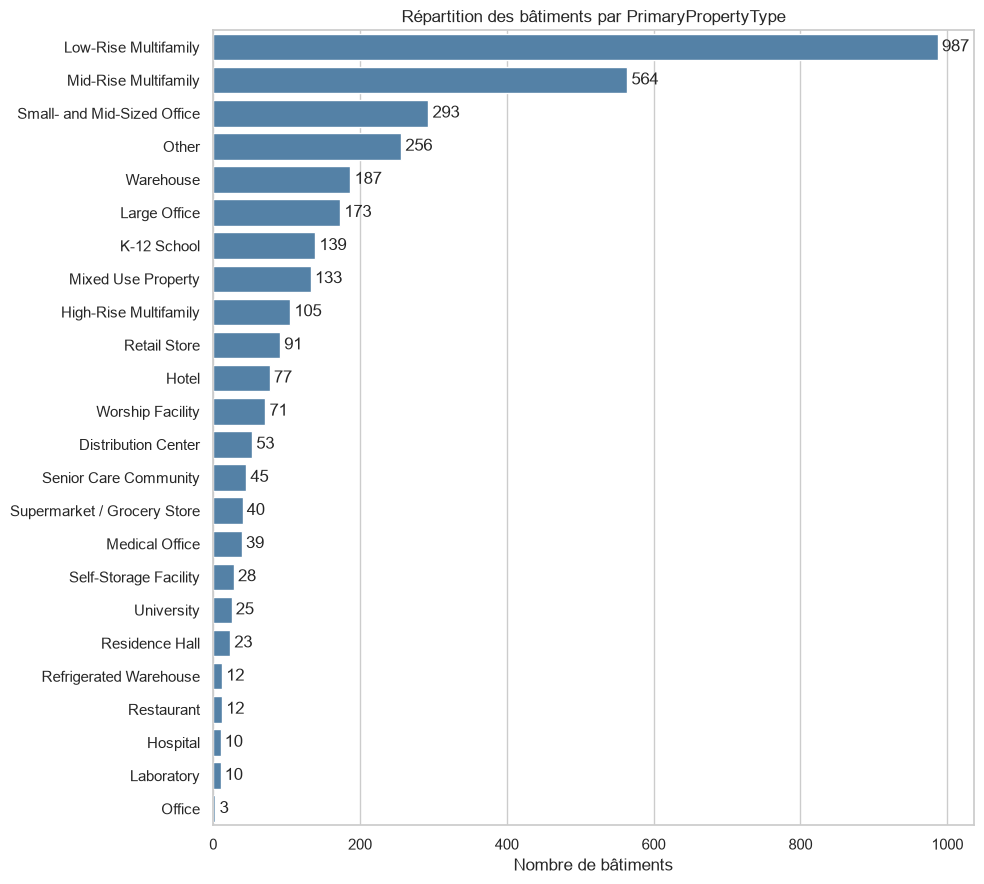

In [ ]:
order = df["PrimaryPropertyType"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 9))
sns.countplot(data=df, y="PrimaryPropertyType", order=order, color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Répartition des bâtiments par PrimaryPropertyType")
ax.set_xlabel("Nombre de bâtiments")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Répartition des PropertyName par PrimaryPropertyType

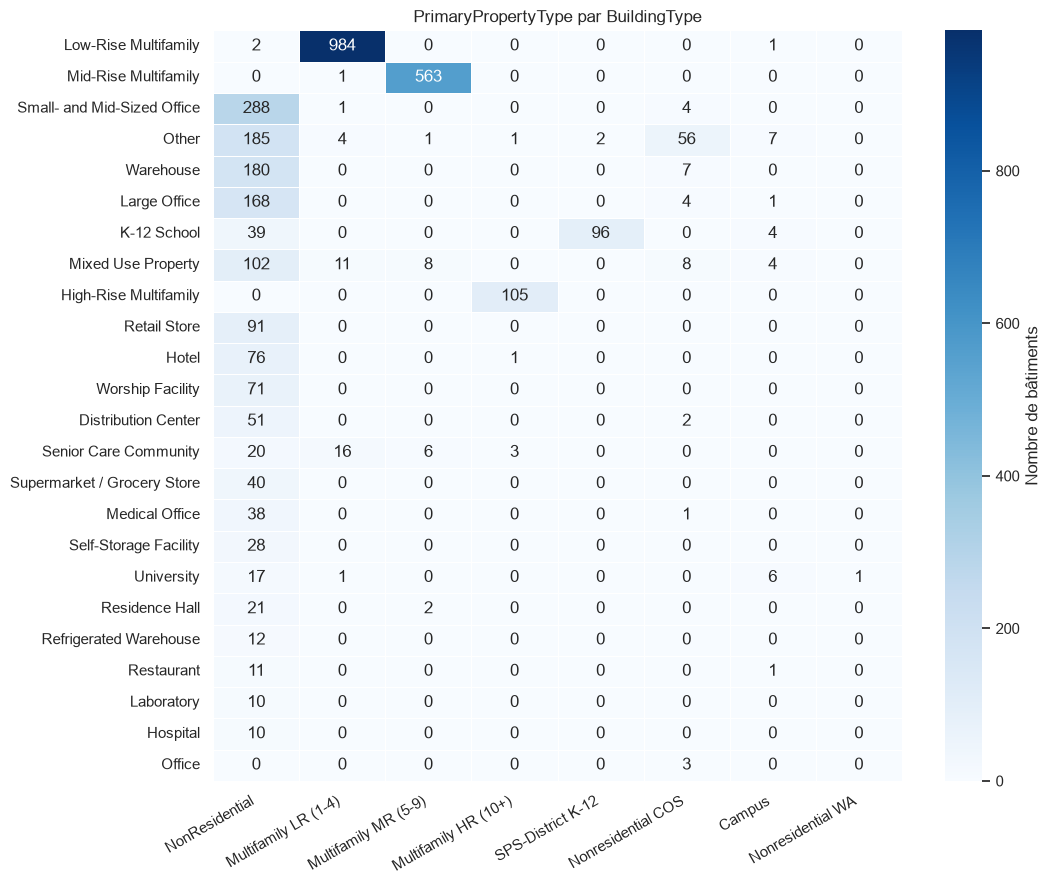

In [ ]:
ct = pd.crosstab(df["PrimaryPropertyType"], df["BuildingType"])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index,
            ct.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "Nombre de bâtiments"}, ax=ax)
ax.set_title("PrimaryPropertyType par BuildingType")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
df.head(10)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2.003882e+06,1.156514e+06,3946027.0,12764.529300,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.000000e+00,9.504252e+05,3242851.0,51450.816410,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,2.156655e+07,1.451544e+07,49526664.0,14938.000000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2.214446e+06,8.115253e+05,2768924.0,18112.130860,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.000000e+00,1.573449e+06,5368607.0,88039.984380,8803998.0,False,NaN,Compliant,NaN,505.01,2.88
5,9,2016,Nonresidential COS,Other,West Precinct,810 Virginia St,Seattle,WA,98101.0,0660000560,7,DOWNTOWN,47.61623,-122.33657,1999,1.0,2,97288,37198,60090,Police Station,Police Station,88830.0,NaN,NaN,NaN,NaN,NaN,NaN,136.100006,141.600006,316.299988,320.500000,12086616.0,12581712.0,0.000000e+00,2.160444e+06,7371434.0,47151.816410,4715182.0,False,NaN,Compliant,NaN,301.81,3.10
6,10,2016,NonResidential,Hotel,Camlin,1619 9th Avenue,Seattle,WA,98101.0,0660000825,7,DOWNTOWN,47.61390,-122.33283,1926,1.0,11,83008,0,83008,Hotel,Hotel,81352.0,NaN,NaN,NaN,NaN,NaN,27.0,70.800003,74.500000,146.600006,154.699997,5758795.0,6062767.5,0.000000e+00,8.239199e+05,2811215.0,29475.800780,2947580.0,False,NaN,Compliant,NaN,176.14,2.12
7,11,2016,NonResidential,Other,Paramount Theatre,911 Pine St,Seattle,WA,98101.0,0660000955,7,DOWNTOWN,47.61327,-122.33136,1926,1.0,8,102761,0,102761,Other - Entertainment/Public Assembly,Other - Entertainment/Public Assembly,102761.0,NaN,NaN,NaN,NaN,NaN,NaN,61.299999,68.800003,141.699997,152.300003,6298131.5,7067881.5,2.276286e+06,1.065843e+06,3636655.0,3851.890137,385189.0,False,NaN,Compliant,NaN,221.51,2.16
8,12,2016,NonResidential,Hotel,311wh-Pioneer Square,612 2nd Ave,Seattle,WA,98104.0,0939000080,7,DOWNTOWN,47.60294,-122.33263,1904,1.0,15,163984,0,163984,Hotel,Hotel,163984.0,Na

Usage du batiment tel qu il est mentionné dans Portfolio Manager / nb d'usages(ListOfAllPropertyUseTypes) par LargestPropertyUseType

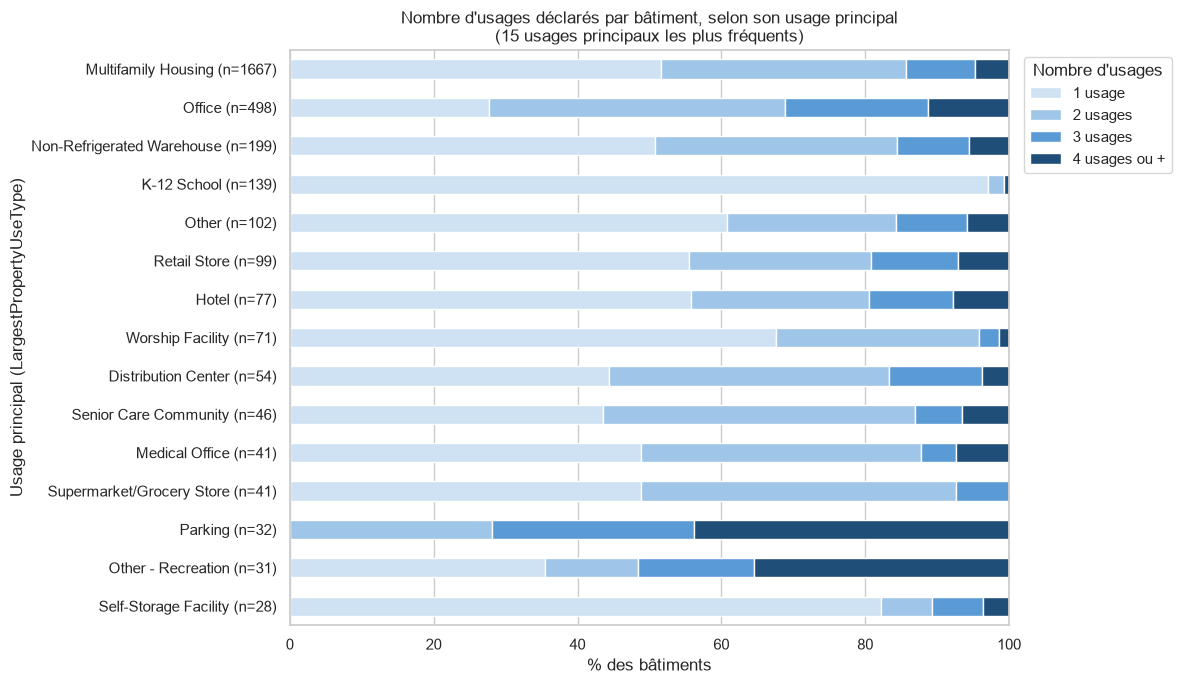

In [ ]:
# Combien d'usages différents déclare chaque type de bâtiment ?
d = df[["LargestPropertyUseType", "ListOfAllPropertyUseTypes"]].dropna().copy()
d["nb_usages"] = d["ListOfAllPropertyUseTypes"].str.split(r",\s*(?![^()]*\))").str.len().clip(upper=4)
d["nb_usages"] = d["nb_usages"].map({1: "1 usage", 2: "2 usages", 3: "3 usages", 4: "4 usages ou +"})

top_main = d["LargestPropertyUseType"].value_counts().head(15).index
pct = (pd.crosstab(d["LargestPropertyUseType"], d["nb_usages"], normalize="index") * 100)
pct = pct.loc[top_main, ["1 usage", "2 usages", "3 usages", "4 usages ou +"]]
n = d["LargestPropertyUseType"].value_counts()
pct.index = [f"{i} (n={n[i]})" for i in pct.index]

ax = pct.iloc[::-1].plot(kind="barh", stacked=True, figsize=(12, 7),
                         color=["#cfe2f3", "#9fc5e8", "#5b9bd5", "#1f4e79"])
ax.set_title("Nombre d'usages déclarés par bâtiment, selon son usage principal\n"
             "(15 usages principaux les plus fréquents)")
ax.set_xlabel("% des bâtiments")
ax.set_ylabel("Usage principal (LargestPropertyUseType)")
ax.set_xlim(0, 100)
ax.legend(title="Nombre d'usages", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

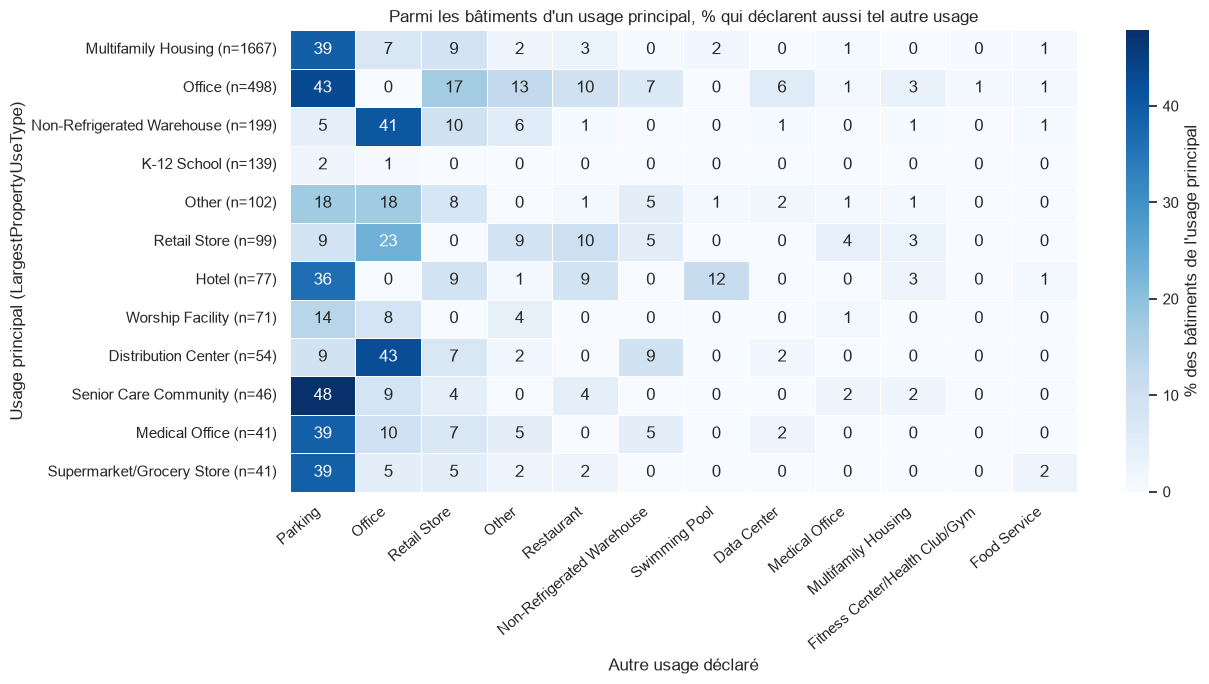

In [ ]:
uses = (df[["LargestPropertyUseType", "ListOfAllPropertyUseTypes"]].dropna()
          .assign(use=lambda d: d["ListOfAllPropertyUseTypes"].str.split(r",\s*(?![^()]*\))"))
          .explode("use"))
uses = uses[uses["use"] != uses["LargestPropertyUseType"]]

top_main = df["LargestPropertyUseType"].value_counts().head(12).index
top_other = uses["use"].value_counts().head(12).index
n_main = df["LargestPropertyUseType"].value_counts()

pct = (pd.crosstab(uses["LargestPropertyUseType"], uses["use"])
         .reindex(index=top_main, columns=top_other, fill_value=0)
         .div(n_main.reindex(top_main), axis=0) * 100)
pct.index = [f"{i} (n={n_main[i]})" for i in pct.index]

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(pct, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, vmin=0,
            cbar_kws={"label": "% des bâtiments de l'usage principal"}, ax=ax)
ax.set_title("Parmi les bâtiments d'un usage principal, % qui déclarent aussi tel autre usage")
ax.set_xlabel("Autre usage déclaré")
ax.set_ylabel("Usage principal (LargestPropertyUseType)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

## Analyse Géographique

In [ ]:
fig = px.density_map(
    df, lat="Latitude", lon="Longitude",
    radius=12, zoom=10.5, height=650,
    center={"lat": df["Latitude"].mean(), "lon": df["Longitude"].mean()},
    map_style="open-street-map",
    title="Concentration des bâtiments à Seattle",
)
fig.show()

Répartition paz Zip Code

In [ ]:
print(f"{df['ZipCode'].nunique()} codes postaux distincts ({df['ZipCode'].isna().sum()} valeurs manquantes)")

(df.dropna(subset=["ZipCode"])
   .assign(ZipCode=lambda d: d["ZipCode"].astype(int))
   .groupby("ZipCode")
   .agg(City=("City", lambda s: ", ".join(sorted(s.dropna().unique()))),
        State=("State", lambda s: ", ".join(sorted(s.dropna().unique()))),
        Nombre_de_batiments=("ZipCode", "size"))
   .reset_index())

55 codes postaux distincts (16 valeurs manquantes)


,ZipCode,City,State,Nombre_de_batiments
0,98006,Seattle,WA,1
1,98011,Seattle,WA,1
2,98012,Seattle,WA,1
3,98013,Seattle,WA,2
4,98020,Seattle,WA,1
5,98028,Seattle,WA,1
6,98033,Seattle,WA,1
7,98040,Seattle,WA,1
8,98053,Seattle,WA,1
9,98070,Seattle,WA,1


Répartition des batiments par parcelles

In [ ]:
parcels = df["TaxParcelIdentificationNumber"]
counts = parcels.value_counts()
print(f"{parcels.nunique()} numéros de parcelle distincts pour {len(df)} lignes "
      f"({parcels.isna().sum()} valeurs manquantes)")
print(f"{(counts > 1).sum()} parcelles partagées par plusieurs bâtiments")

table = counts.rename_axis("TaxParcelIdentificationNumber").reset_index(name="Nombre de bâtiments")
with pd.option_context("display.max_rows", None):
    display(table.head(80))

3268 numéros de parcelle distincts pour 3376 lignes (0 valeurs manquantes)
77 parcelles partagées par plusieurs bâtiments


,TaxParcelIdentificationNumber,Nombre de bâtiments
0,1625049001,8
1,0002400002,5
2,3224049012,5
3,0925049346,5
4,3624039009,4
5,8632880000,4
6,7666203240,4
7,1985200003,3
8,0164000222,3
9,0939000300,3


Répartition par CouncilDistrictCode

In [ ]:
districts = df["CouncilDistrictCode"]
counts = districts.value_counts()
print(f"{districts.nunique()} districts distincts pour {len(df)} lignes "
      f"({districts.isna().sum()} valeurs manquantes)")

table = counts.rename_axis("CouncilDistrictCode").reset_index(name="Nombre de bâtiments")
with pd.option_context("display.max_rows", None):
    display(table.head(80))

7 districts distincts pour 3376 lignes (0 valeurs manquantes)


,CouncilDistrictCode,Nombre de bâtiments
0,7,1037
1,3,596
2,2,509
3,4,367
4,5,338
5,1,282
6,6,247


Répartition par Neighborhood

In [ ]:
districts = df["Neighborhood"]
counts = districts.value_counts()
print(f"{districts.nunique()} districts distincts pour {len(df)} lignes "
      f"({districts.isna().sum()} valeurs manquantes)")

table = counts.rename_axis("Neighborhood").reset_index(name="Nombre de bâtiments")
with pd.option_context("display.max_rows", None):
    display(table.head(80))

19 districts distincts pour 3376 lignes (0 valeurs manquantes)


,Neighborhood,Nombre de bâtiments
0,DOWNTOWN,573
1,EAST,453
2,MAGNOLIA / QUEEN ANNE,423
3,GREATER DUWAMISH,375
4,NORTHEAST,280
5,LAKE UNION,251
6,NORTHWEST,210
7,SOUTHWEST,166
8,NORTH,145
9,BALLARD,126


Vision entonnoir de la Map

In [ ]:
geo_df = df.assign(
    CouncilDistrictCode="D" + df["CouncilDistrictCode"].astype(str),
    Neighborhood=df["Neighborhood"].str.upper(),
    ZipCode=df["ZipCode"].astype("Int64").astype(str).fillna("Inconnu"),
)

tm = geo_df.assign(
    District="District " + df["CouncilDistrictCode"].astype(str),
    Quartier=df["Neighborhood"].str.title(),
    CodePostal="ZIP " + df["ZipCode"].astype("Int64").astype(str).fillna("inconnu"),
)

fig = px.treemap(
    tm, path=[px.Constant("Seattle"), "District", "Quartier", "CodePostal"],
    color="District", height=700,
    color_discrete_sequence=px.colors.qualitative.Safe,
    title="Nombre de bâtiments par<br>"
          "District → Quartier → Code postal</sup>",
)
fig.update_traces(
    textinfo="label+value+percent parent",
    texttemplate="%{label}<br>%{value} bât. (%{percentParent:.0%})",
    hovertemplate="<b>%{label}</b><br>Bâtiments : %{value}<br>"
                  "Part du niveau supérieur : %{percentParent:.1%}<br>"
                  "Part du total : %{percentRoot:.1%}<extra></extra>",
    root_color="lightgrey",
)
fig.update_layout(margin={"t": 90, "l": 10, "r": 10, "b": 10})
fig.show()

plutot que le code postale (zipcode) qui n a pas de sens pour le modèle renseigner le nb de batiments par zip code : NbBatiments_ZIP

a un impact avéré sur la target ds matrice de corélation

In [ ]:
geo_df = df.assign(
    CouncilDistrictCode="D" + df["CouncilDistrictCode"].astype(str),
    Neighborhood=df["Neighborhood"].str.upper(),
    ZipCode=df["ZipCode"].astype("Int64").astype(str).fillna("Inconnu"),
)

tm = geo_df.assign(
    District="District " + df["CouncilDistrictCode"].astype(str),
    Quartier=df["Neighborhood"].str.title(),
    CodePostal="ZIP " + df["ZipCode"].astype("Int64").astype(str).fillna("inconnu"),
)

tm["NbBatiments_ZIP"] = tm.groupby(["District", "Quartier", "CodePostal"])["CodePostal"].transform("count")

fig = px.treemap(
    tm, path=[px.Constant("Seattle"), "District", "Quartier", "CodePostal"],
    color="District", height=700,
    color_discrete_sequence=px.colors.qualitative.Safe,
    title="Nombre de bâtiments par<br>District → Quartier → Code postal",
)

# id Plotly de chaque feuille -> valeur de la colonne NbBatiments_ZIP
feuilles = tm.drop_duplicates(["District", "Quartier", "CodePostal"])
nb_par_id = {
    f"Seattle/{r.District}/{r.Quartier}/{r.CodePostal}": r.NbBatiments_ZIP
    for r in feuilles.itertuples()
}

t = fig.data[0]
parents = set(t.parents)
labels = list(t.labels)
for i, id_ in enumerate(t.ids):
    if id_ not in parents:                      
        labels[i] = f"{nb_par_id[id_]} bât."
t.labels = labels

fig.update_traces(
    texttemplate="%{label}",
    hovertemplate="<b>%{id}</b><br>Bâtiments : %{value}<br>"
                  "Part du niveau supérieur : %{percentParent:.1%}<br>"
                  "Part du total : %{percentRoot:.1%}<extra></extra>",
    root_color="lightgrey",
)
fig.update_layout(margin={"t": 90, "l": 10, "r": 10, "b": 10})
fig.show()

df["NbBatiments_ZIP"] = df.groupby("ZipCode")["ZipCode"].transform("count")



Distance des batiments par raport au centre ville (fetaure enginering)

pas interessant peu d'effet sur les target

In [ ]:
CENTRE_LAT, CENTRE_LON = 47.6062, -122.3321   # centre-ville de Seattle (Downtown)

def distance_km(lat, lon, lat0=CENTRE_LAT, lon0=CENTRE_LON):
    """Distance à vol d'oiseau (formule de Haversine), en kilomètres."""
    R = 6371.0   # rayon de la Terre en km
    phi1, phi2 = np.radians(lat), np.radians(lat0)
    dphi = phi2 - phi1
    dlam = np.radians(lon0) - np.radians(lon)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlam / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df["DistanceCentreVille_km"] = distance_km(df["Latitude"], df["Longitude"])


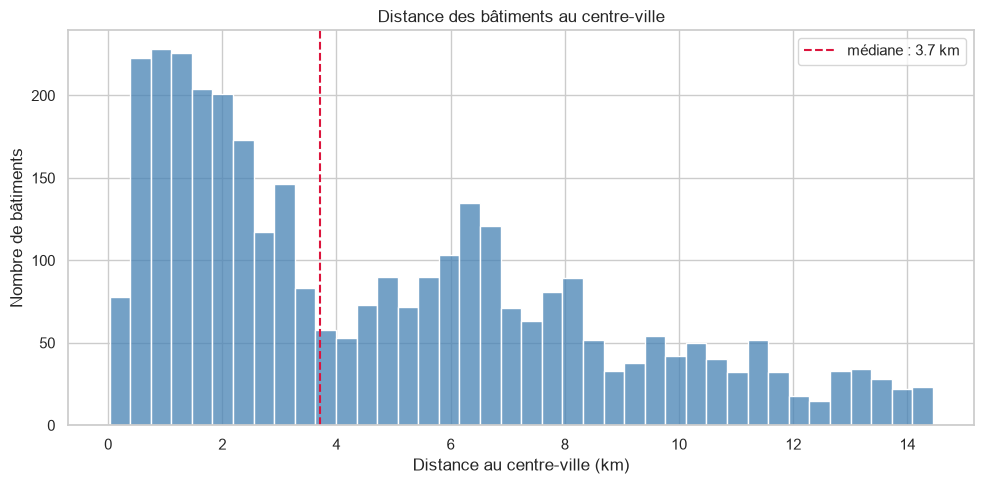

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["DistanceCentreVille_km"], bins=40, color="steelblue", ax=ax)
med = df["DistanceCentreVille_km"].median()
ax.axvline(med, color="crimson", ls="--", label=f"médiane : {med:.1f} km")
ax.set_title("Distance des bâtiments au centre-ville")
ax.set_xlabel("Distance au centre-ville (km)")
ax.set_ylabel("Nombre de bâtiments")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
fig = px.scatter_map(df, lat="Latitude", lon="Longitude", color="DistanceCentreVille_km",
                     color_continuous_scale="Viridis_r", hover_data=["PropertyName", "Neighborhood"],
                     zoom=10.5, center={"lat": df["Latitude"].mean(), "lon": df["Longitude"].mean()}, height=700, map_style="open-street-map",
                     labels={"DistanceCentreVille_km": "Distance (km)"},
                     title="Distance au centre-ville de chaque bâtiment")
fig.add_scattermap(lat=[CENTRE_LAT], lon=[CENTRE_LON], mode="markers",
                   marker={"size": 16, "color": "crimson"}, name="Centre-ville")
fig.show()

In [ ]:
fig = px.scatter_map(df, lat="Latitude", lon="Longitude", color="DistanceCentreVille_km",
                     color_continuous_scale="Viridis_r", hover_data=["PropertyName", "Neighborhood"],
                     zoom=10.5, center={"lat": df["Latitude"].mean(), "lon": df["Longitude"].mean()}, height=700, map_style="open-street-map",
                     labels={"DistanceCentreVille_km": "Distance (km)"},
                     title="Distance au centre-ville de chaque bâtiment")
fig.add_scattermap(lat=[CENTRE_LAT], lon=[CENTRE_LON], mode="markers",
                   marker={"size": 16, "color": "crimson"}, name="Centre-ville")
fig.show()

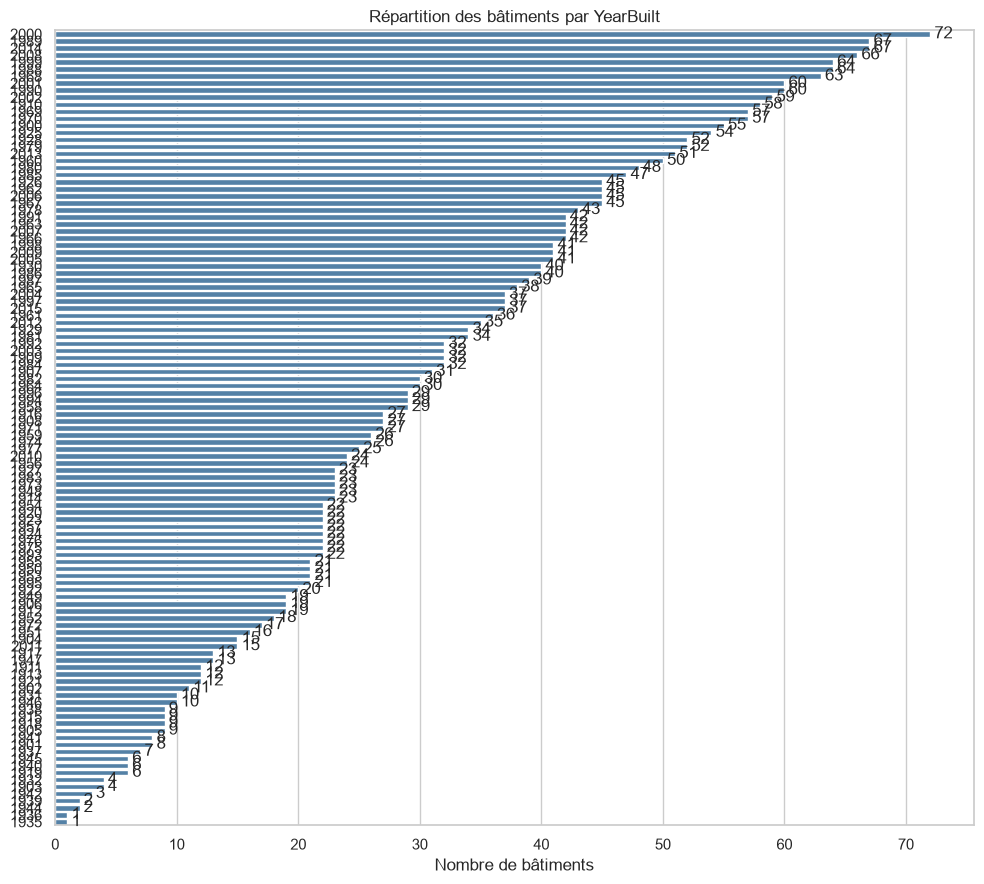

In [ ]:
order = df["YearBuilt"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 9))
sns.countplot(data=df, y="YearBuilt", order=order, color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Répartition des bâtiments par YearBuilt")
ax.set_xlabel("Nombre de bâtiments")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

age du batiment date actuelle - yearBuilt (feature enginering)

In [ ]:
ANNEE_ACTUELLE = date.today().year
df["AgeBatiment"] = ANNEE_ACTUELLE - df["YearBuilt"]


Répartition des bâtiments par âges

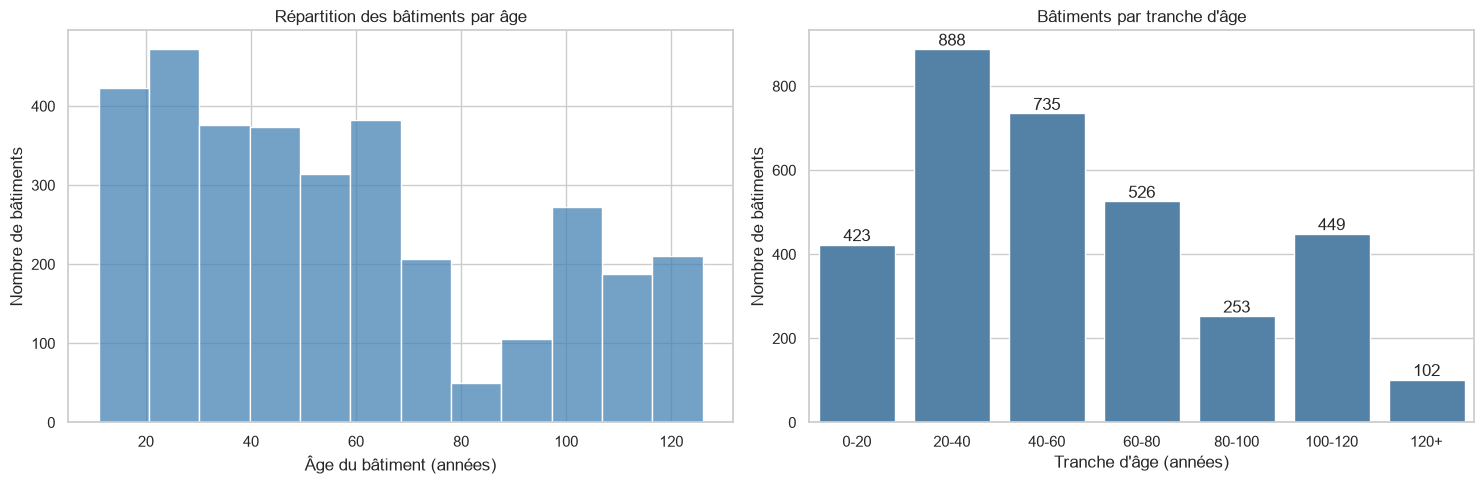

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogramme par tranches de 10 ans
sns.histplot(df["AgeBatiment"], binwidth=10, color="steelblue", ax=axes[0])
axes[0].set(title="Répartition des bâtiments par âge",
            xlabel="Âge du bâtiment (années)", ylabel="Nombre de bâtiments")

# Nombre de bâtiments par tranche d'âge
tranches = pd.cut(
    df["AgeBatiment"],
    bins=[0, 20, 40, 60, 80, 100, 120, 200],
    labels=["0-20", "20-40", "40-60", "60-80", "80-100", "100-120", "120+"],
)
compte = tranches.value_counts().sort_index()
sns.barplot(x=compte.index.astype(str), y=compte.values, color="steelblue", ax=axes[1])
for i, v in enumerate(compte.values):
    axes[1].text(i, v, str(v), ha="center", va="bottom")
axes[1].set(title="Bâtiments par tranche d'âge",
            xlabel="Tranche d'âge (années)", ylabel="Nombre de bâtiments")

plt.tight_layout()
plt.show()


Répartition par nombre de batiments

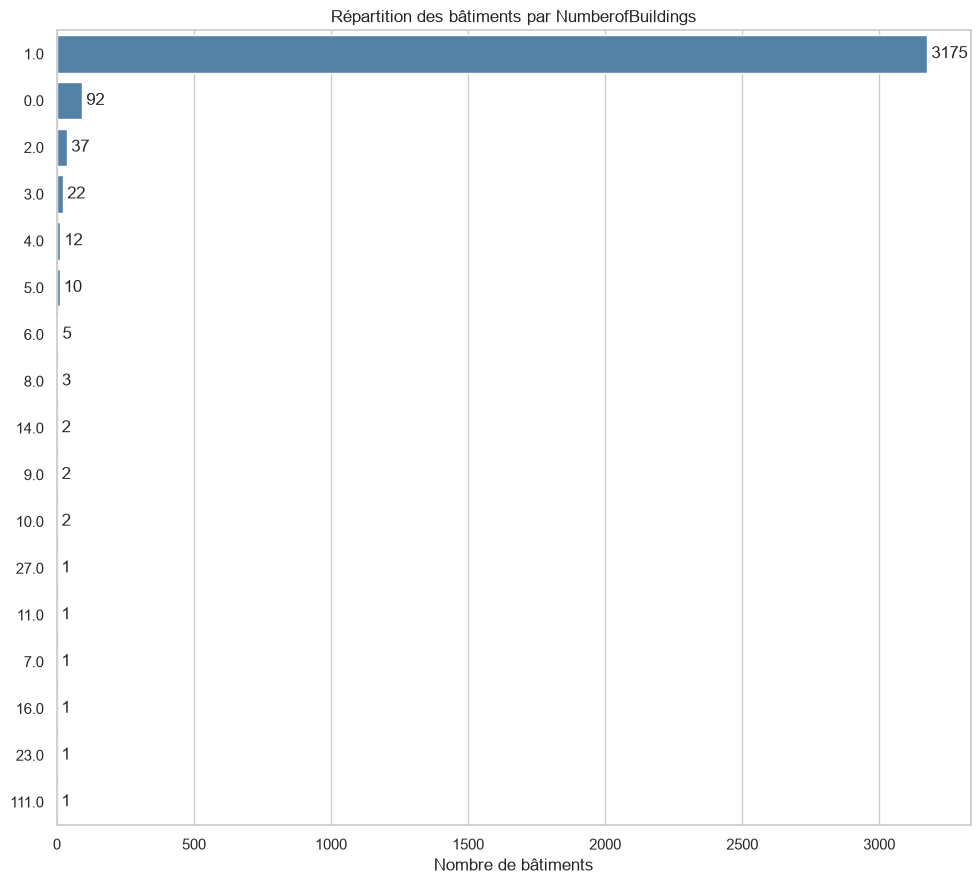

In [ ]:
order = df["NumberofBuildings"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 9))
sns.countplot(data=df, y="NumberofBuildings", order=order, color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Répartition des bâtiments par NumberofBuildings")
ax.set_xlabel("Nombre de bâtiments")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Batiments ayants NumberofBuildings > 1

In [ ]:

multi = (df.loc[df["NumberofBuildings"] > 1,
                ["PropertyName", "BuildingType", "PrimaryPropertyType", "NumberofBuildings"]]
           .sort_values("NumberofBuildings", ascending=False)
           .reset_index(drop=True))
print(f"{len(multi)} propriétés regroupent plusieurs bâtiments")
with pd.option_context("display.max_rows", None):
    display(multi)

101 propriétés regroupent plusieurs bâtiments


,PropertyName,BuildingType,PrimaryPropertyType,NumberofBuildings
0,University of Washington - Seattle Campus,Campus,University,111.0
1,SSCC MAIN CAMPUS,Campus,University,27.0
2,FT C15 Fishermen's Center,Campus,Other,23.0
3,Northline Apartments,Multifamily LR (1-4),Low-Rise Multifamily,16.0
4,South Park,Campus,Large Office,14.0
5,5th Avenue Master Meter,Campus,University,14.0
6,NSCC MAIN CAMPUS,Campus,University,11.0
7,Veridian Cove Condominiums,Multifamily LR (1-4),Low-Rise Multifamily,10.0
8,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,Campus,Other,10.0
9,Harborview Medical Center,NonResidential,Hospital,9.0


In [ ]:
df.head(10)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,NbBatiments_ZIP,DistanceCentreVille_km,AgeBatiment
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2.003882e+06,1.156514e+06,3946027.0,12764.529300,1276453.0,False,NaN,Compliant,NaN,249.98,2.83,230.0,0.800050,99
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.000000e+00,9.504252e+05,3242851.0,51450.816410,5145082.0,False,NaN,Compliant,NaN,295.86,2.86,230.0,0.787077,30
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,2.156655e+07,1.451544e+07,49526664.0,14938.000000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19,230.0,0.970109,57
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2.214446e+06,8.115253e+05,2768924.0,18112.130860,1811213.0,False,NaN,Compliant,NaN,286.43,4.67,230.0,0.944139,100
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.000000e+00,1.573449e+06,5368607.0,88039.984380,8803998.0,False,NaN,Compliant,NaN,505.01,2.88,186.0,1.048092,46
5,9,2016,Nonresidential COS,Other,West Precinct,810 Virginia St,Seattle,WA,98101.0,0660000560,7,DOWNTOWN,47.61623,-122.33657,1999,1.0,2,97288,37198,60090,Police Station,Police Station,88830.0,NaN,NaN,NaN,NaN,NaN,NaN,136.100006,141.600006,316.299988,320.500000,12086616.0,12581712.0,0.000000e+00,2.160444e+06,7371434.0,47151.816410,4715182.0,False,NaN,Compliant,NaN,301.81,3.10,230.0,1.164535,27
6,10,2016,NonResidential,Hotel,Camlin,1619 9th Avenue,Seattle,WA,98101.0,0660000825,7,DOWNTOWN,47.61390,-122.33283,1926,1.0,11,83008,0,83008,Hotel,Hotel,81352.0,NaN,NaN,NaN,NaN,NaN,27.0,70.800003,74.500000,146.600006,154.699997,5758795.0,6062767.5,0.000000e+00,8.239199e+05,2811215.0,29475.800780,2947580.0,False,NaN,Compliant,NaN,176.14,2.12,230.0,0.857948,100
7,11,2016,NonResidential,Other,Paramount Theatre,911 Pine St,Seattle,WA,98101.0,0660000955,7,DOWNTOWN,47.61327,-122.33136,1926,1.0,8,102761,0,102761,Other - Entertainment/Public Assembly,Other - Entertainment/Public Assembly,102761.0,NaN,NaN,NaN,NaN,NaN,NaN,61.299999,68.800003,141.699997,152.300003,6298131.5,7067881.5,2.276286e+06,1.065843e+06,3636655.0,3851.890137,385189.0,False,NaN,Compliant,NaN,221.51,2.

## Nombre d'étages par bâtiments

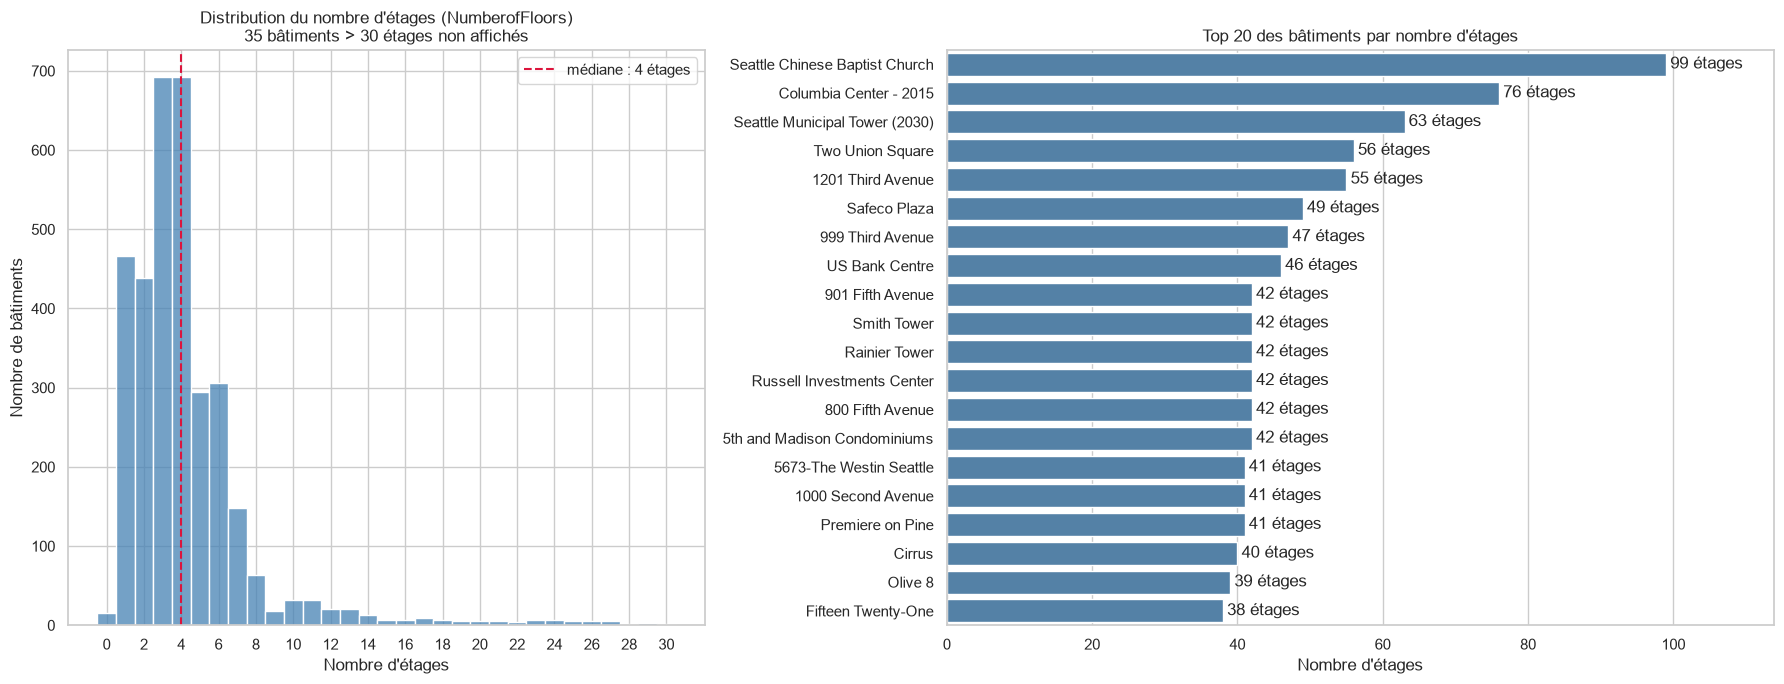

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.3]})

floors = df["NumberofFloors"]
n_above = (floors > 30).sum()
sns.histplot(floors[floors <= 30], discrete=True, color="steelblue", ax=axes[0])
axes[0].axvline(floors.median(), color="crimson", ls="--",
                label=f"médiane : {floors.median():.0f} étages")
axes[0].set_xticks(range(0, 31, 2))
axes[0].set_title(f"Distribution du nombre d'étages (NumberofFloors)\n{n_above} bâtiments > 30 étages non affichés")
axes[0].set_xlabel("Nombre d'étages")
axes[0].set_ylabel("Nombre de bâtiments")
axes[0].legend()

top = df.nlargest(20, "NumberofFloors")
sns.barplot(data=top, y="PropertyName", x="NumberofFloors", color="steelblue", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="{:.0f} étages", padding=3)
axes[1].set_title("Top 20 des bâtiments par nombre d'étages")
axes[1].set_xlabel("Nombre d'étages")
axes[1].set_ylabel("")
axes[1].set_xlim(0, top["NumberofFloors"].max() * 1.15)

plt.tight_layout()
plt.show()

## Superficie des terrains par bâtiment

PropertyGFATotal

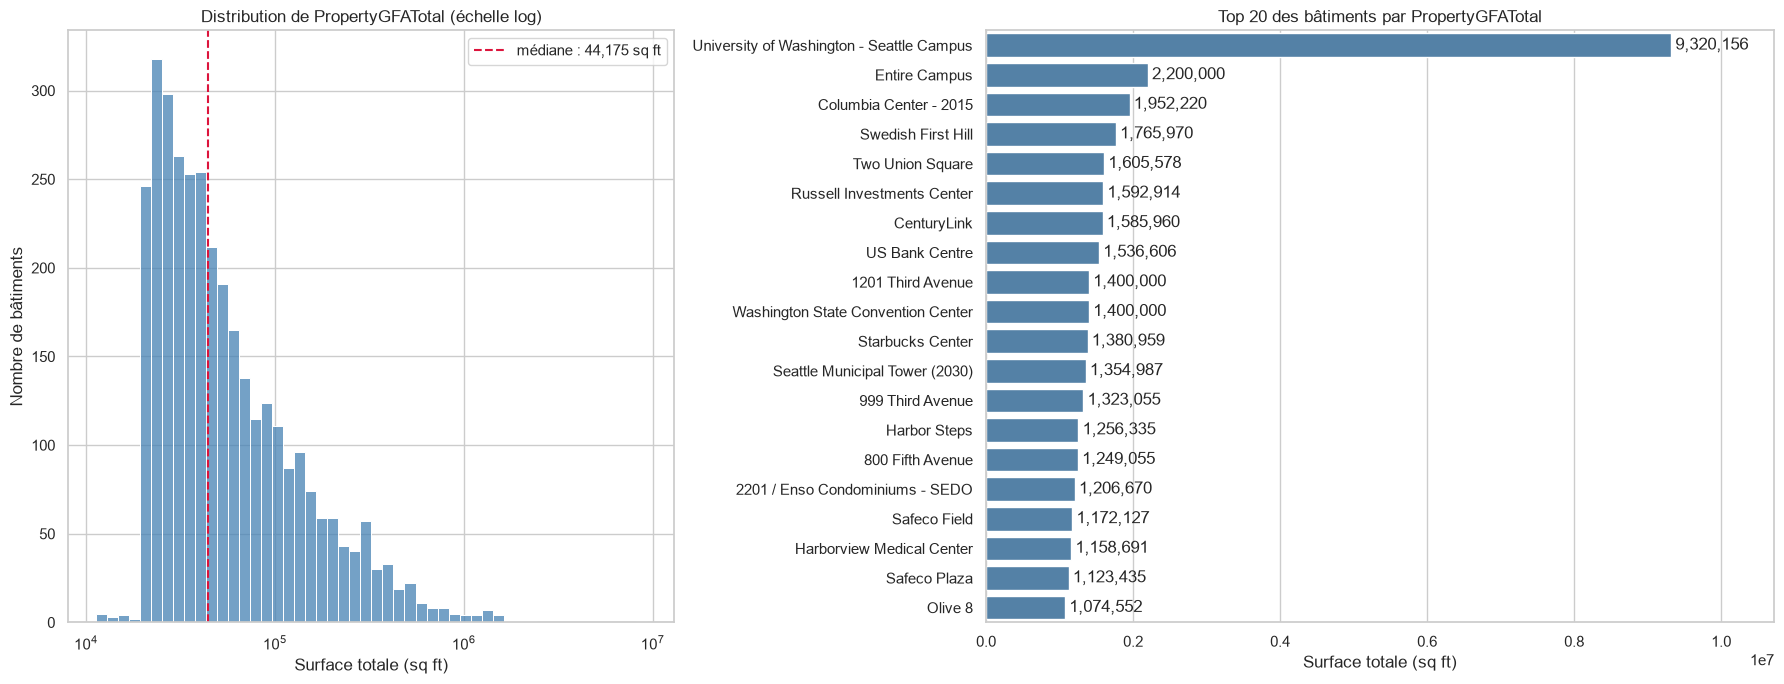

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.3]})

# Distribution sur l'ensemble des bâtiments (échelle log car très asymétrique)
sns.histplot(df["PropertyGFATotal"], bins=50, log_scale=True, color="steelblue", ax=axes[0])
axes[0].axvline(df["PropertyGFATotal"].median(), color="crimson", ls="--",
                label=f"médiane : {df['PropertyGFATotal'].median():,.0f} sq ft")
axes[0].set_title("Distribution de PropertyGFATotal (échelle log)")
axes[0].set_xlabel("Surface totale (sq ft)")
axes[0].set_ylabel("Nombre de bâtiments")
axes[0].legend()

# Les 20 plus grands bâtiments
top = df.nlargest(20, "PropertyGFATotal")
sns.barplot(data=top, y="PropertyName", x="PropertyGFATotal", color="steelblue", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", padding=3)
axes[1].set_title("Top 20 des bâtiments par PropertyGFATotal")
axes[1].set_xlabel("Surface totale (sq ft)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, top["PropertyGFATotal"].max() * 1.15)

plt.tight_layout()
plt.show()

PropertyGFAParking

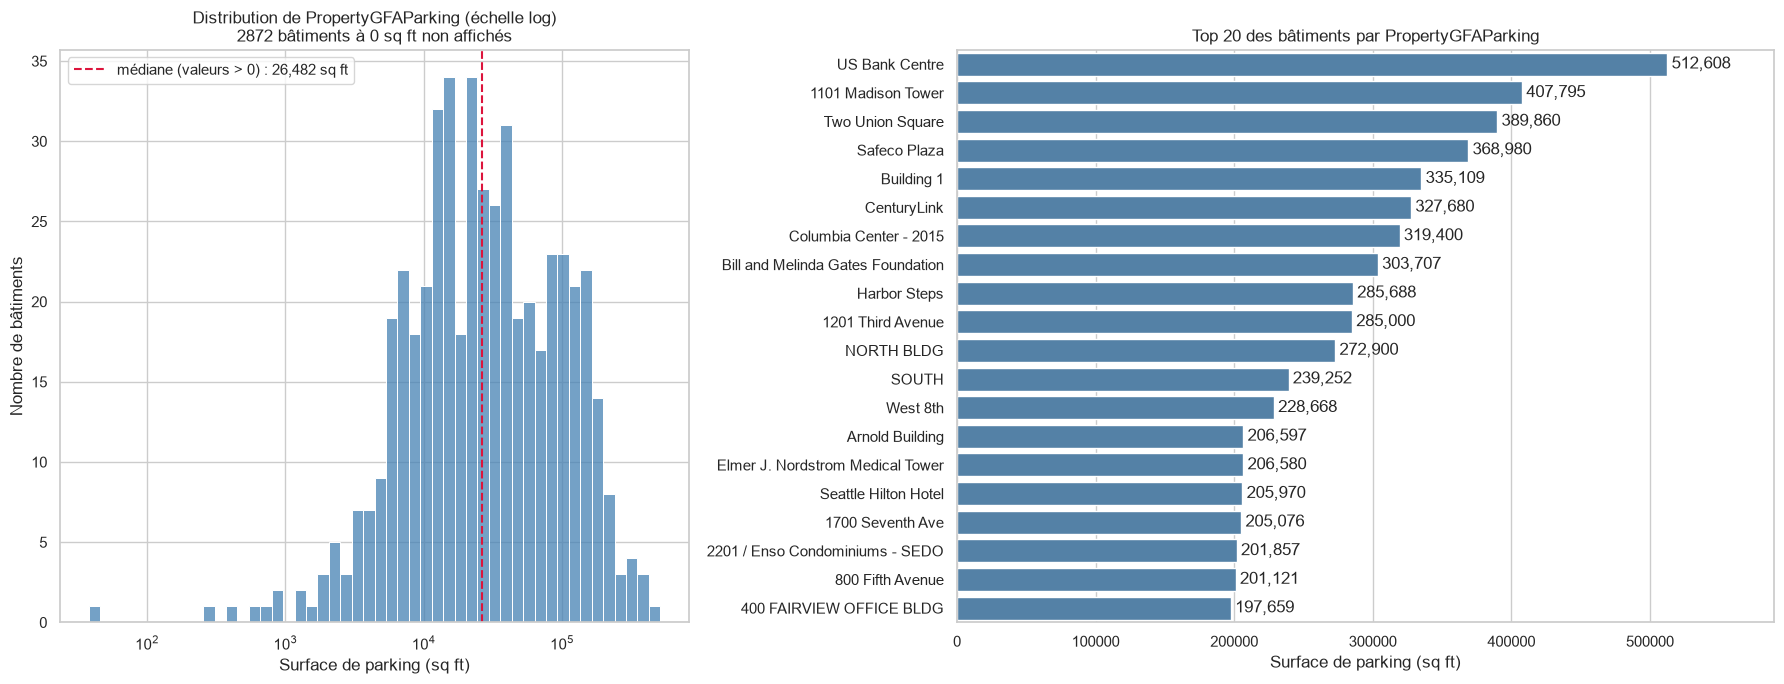

In [ ]:
col = "PropertyGFAParking"
label = "Surface de parking"
vals = df[col]
pos = vals[vals > 0]

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.3]})

# Distribution (échelle log car très asymétrique ; les valeurs nulles ne peuvent pas y figurer)
sns.histplot(pos, bins=50, log_scale=True, color="steelblue", ax=axes[0])
axes[0].axvline(pos.median(), color="crimson", ls="--",
                label=f"médiane (valeurs > 0) : {pos.median():,.0f} sq ft")
axes[0].set_title(f"Distribution de {col} (échelle log)\n{(vals == 0).sum()} bâtiments à 0 sq ft non affichés")
axes[0].set_xlabel(f"{label} (sq ft)")
axes[0].set_ylabel("Nombre de bâtiments")
axes[0].legend()

# Les 20 plus grands bâtiments
top = df.nlargest(20, col)
sns.barplot(data=top, y="PropertyName", x=col, color="steelblue", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", padding=3)
axes[1].set_title(f"Top 20 des bâtiments par {col}")
axes[1].set_xlabel(f"{label} (sq ft)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, top[col].max() * 1.15)

plt.tight_layout()
plt.show()

ajouter colonne % surface du parking sur surface totale (feature enginering)


In [ ]:
df.head(10)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,NbBatiments_ZIP,DistanceCentreVille_km,AgeBatiment
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2.003882e+06,1.156514e+06,3946027.0,12764.529300,1276453.0,False,NaN,Compliant,NaN,249.98,2.83,230.0,0.800050,99
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.000000e+00,9.504252e+05,3242851.0,51450.816410,5145082.0,False,NaN,Compliant,NaN,295.86,2.86,230.0,0.787077,30
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,2.156655e+07,1.451544e+07,49526664.0,14938.000000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19,230.0,0.970109,57
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2.214446e+06,8.115253e+05,2768924.0,18112.130860,1811213.0,False,NaN,Compliant,NaN,286.43,4.67,230.0,0.944139,100
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.000000e+00,1.573449e+06,5368607.0,88039.984380,8803998.0,False,NaN,Compliant,NaN,505.01,2.88,186.0,1.048092,46
5,9,2016,Nonresidential COS,Other,West Precinct,810 Virginia St,Seattle,WA,98101.0,0660000560,7,DOWNTOWN,47.61623,-122.33657,1999,1.0,2,97288,37198,60090,Police Station,Police Station,88830.0,NaN,NaN,NaN,NaN,NaN,NaN,136.100006,141.600006,316.299988,320.500000,12086616.0,12581712.0,0.000000e+00,2.160444e+06,7371434.0,47151.816410,4715182.0,False,NaN,Compliant,NaN,301.81,3.10,230.0,1.164535,27
6,10,2016,NonResidential,Hotel,Camlin,1619 9th Avenue,Seattle,WA,98101.0,0660000825,7,DOWNTOWN,47.61390,-122.33283,1926,1.0,11,83008,0,83008,Hotel,Hotel,81352.0,NaN,NaN,NaN,NaN,NaN,27.0,70.800003,74.500000,146.600006,154.699997,5758795.0,6062767.5,0.000000e+00,8.239199e+05,2811215.0,29475.800780,2947580.0,False,NaN,Compliant,NaN,176.14,2.12,230.0,0.857948,100
7,11,2016,NonResidential,Other,Paramount Theatre,911 Pine St,Seattle,WA,98101.0,0660000955,7,DOWNTOWN,47.61327,-122.33136,1926,1.0,8,102761,0,102761,Other - Entertainment/Public Assembly,Other - Entertainment/Public Assembly,102761.0,NaN,NaN,NaN,NaN,NaN,NaN,61.299999,68.800003,141.699997,152.300003,6298131.5,7067881.5,2.276286e+06,1.065843e+06,3636655.0,3851.890137,385189.0,False,NaN,Compliant,NaN,221.51,2.

Répartition selon la surface du bâtiment

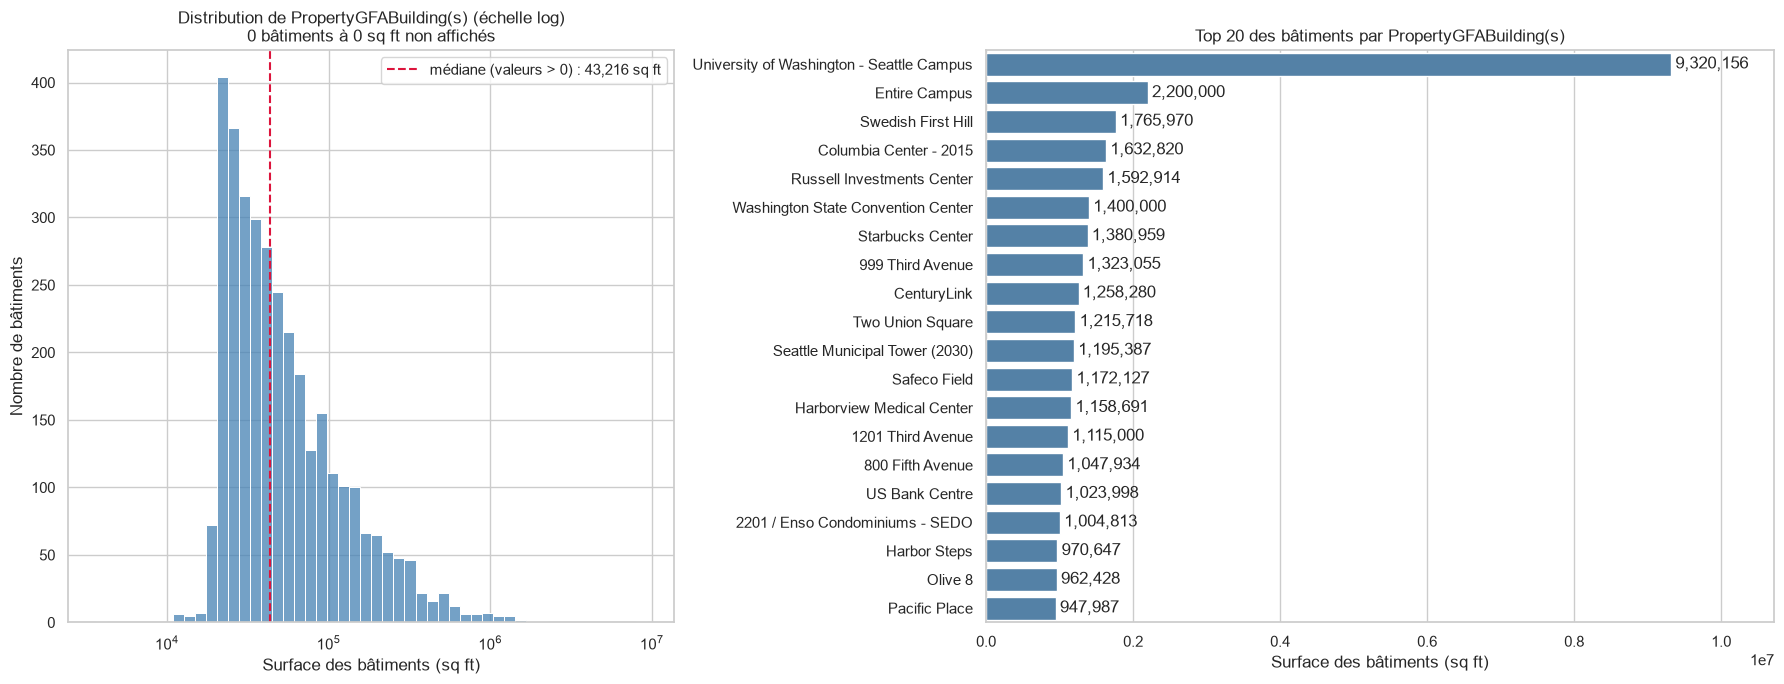

In [ ]:
col = "PropertyGFABuilding(s)"
label = "Surface des bâtiments"
vals = df[col]
pos = vals[vals > 0]

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.3]})

# Distribution (échelle log car très asymétrique ; les valeurs nulles ne peuvent pas y figurer)
sns.histplot(pos, bins=50, log_scale=True, color="steelblue", ax=axes[0])
axes[0].axvline(pos.median(), color="crimson", ls="--",
                label=f"médiane (valeurs > 0) : {pos.median():,.0f} sq ft")
axes[0].set_title(f"Distribution de {col} (échelle log)\n{(vals == 0).sum()} bâtiments à 0 sq ft non affichés")
axes[0].set_xlabel(f"{label} (sq ft)")
axes[0].set_ylabel("Nombre de bâtiments")
axes[0].legend()

# Les 20 plus grands bâtiments
top = df.nlargest(20, col)
sns.barplot(data=top, y="PropertyName", x=col, color="steelblue", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", padding=3)
axes[1].set_title(f"Top 20 des bâtiments par {col}")
axes[1].set_xlabel(f"{label} (sq ft)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, top[col].max() * 1.15)

plt.tight_layout()
plt.show()

### ENERGYSTARScore

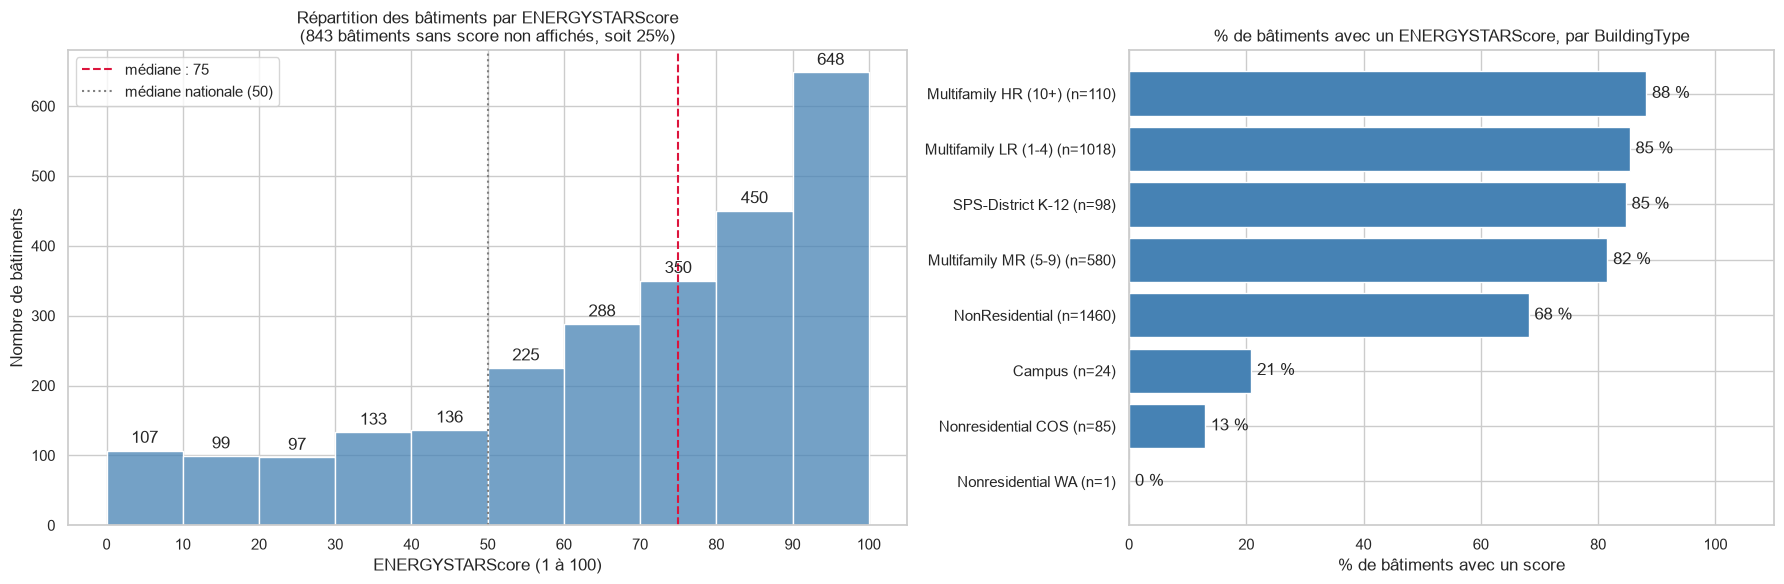

In [ ]:
score = df["ENERGYSTARScore"]
n_missing = score.isna().sum()

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.3, 1]})

# Distribution des scores renseignés (tranches de 10 points)
sns.histplot(score.dropna(), bins=range(0, 101, 10), color="steelblue", ax=axes[0])
axes[0].axvline(score.median(), color="crimson", ls="--", label=f"médiane : {score.median():.0f}")
axes[0].axvline(50, color="grey", ls=":", label="médiane nationale (50)")
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_xticks(range(0, 101, 10))
axes[0].set_title(f"Répartition des bâtiments par ENERGYSTARScore\n({n_missing} bâtiments sans score non affichés, soit {n_missing / len(df):.0%})")
axes[0].set_xlabel("ENERGYSTARScore (1 à 100)")
axes[0].set_ylabel("Nombre de bâtiments")
axes[0].legend()

# Part des bâtiments qui ont un score, par BuildingType
avail = (df.assign(a=score.notna()).groupby("BuildingType")["a"].agg(["mean", "size"])
           .sort_values("mean"))
axes[1].barh([f"{i} (n={n})" for i, n in zip(avail.index, avail["size"])], avail["mean"] * 100, color="steelblue")
for i, v in enumerate(avail["mean"] * 100):
    axes[1].text(v + 1, i, f"{v:.0f} %", va="center")
axes[1].set_xlim(0, 110)
axes[1].set_title("% de bâtiments avec un ENERGYSTARScore, par BuildingType")
axes[1].set_xlabel("% de bâtiments avec un score")

plt.tight_layout()
plt.show()

## Supression des bâtiments Résidentiels

In [ ]:
targets = ["TotalGHGEmissions", "SiteEnergyUse(kBtu)"]

df = df[~df["BuildingType"].str.startswith("Multifamily")].dropna(subset=targets)
df = df[(df[targets] > 0).all(axis=1)].copy()


### Outliers selon le type de bâtiments

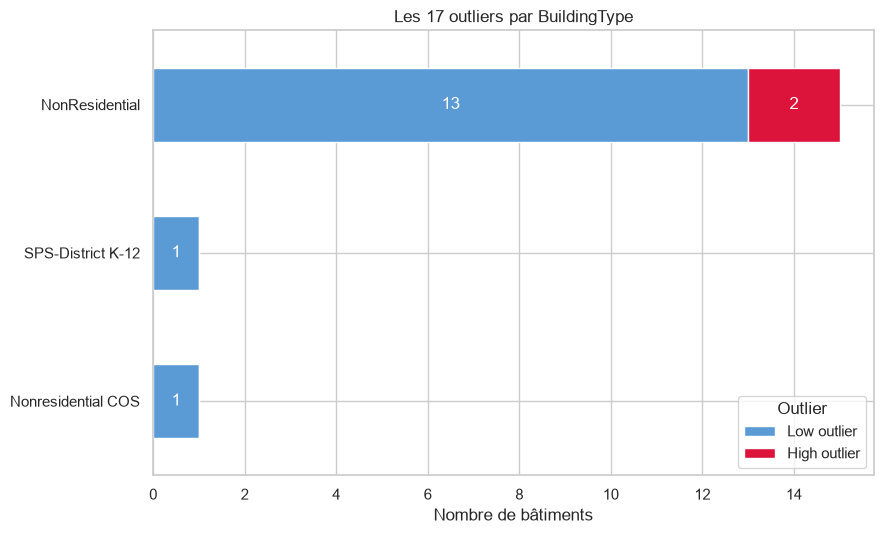

In [ ]:
colors = {"Low outlier": "#5b9bd5", "High outlier": "crimson"}

only = df[df["Outlier"].notna()]
ct = pd.crosstab(only["BuildingType"], only["Outlier"]).reindex(columns=["Low outlier", "High outlier"], fill_value=0)
ct = ct.loc[ct.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 5.5))
ct.plot(kind="barh", stacked=True, color=[colors["Low outlier"], colors["High outlier"]], ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, label_type="center", color="white",
                 labels=[int(v) if v > 0 else "" for v in cont.datavalues])
ax.set_title(f"Les {len(only)} outliers par BuildingType")
ax.set_xlabel("Nombre de bâtiments")
ax.set_ylabel("")
ax.legend(title="Outlier")

plt.tight_layout()
plt.show()


source : https://www.seattle.gov/documents/departments/ose/ebr-data-accuracy.pdf

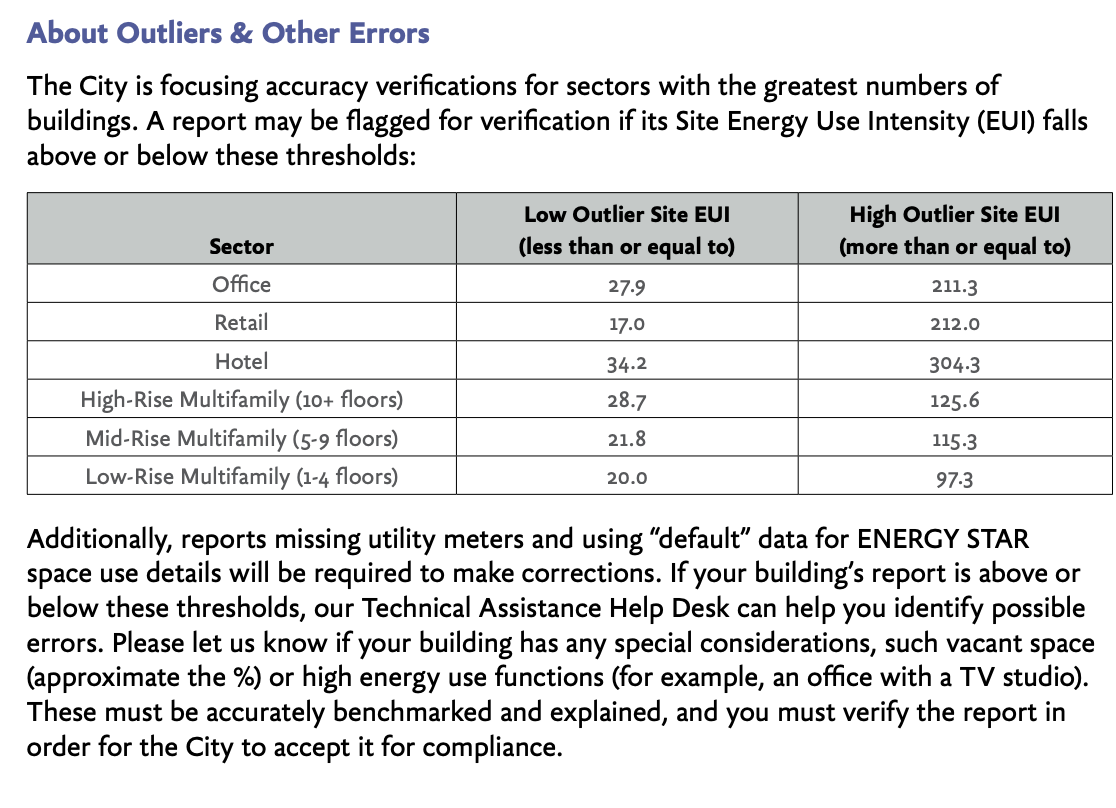

In [ ]:
cols = ["PropertyName", "BuildingType", "PrimaryPropertyType", "Neighborhood",
        "YearBuilt", "PropertyGFATotal", "SiteEnergyUse(kBtu)", "TotalGHGEmissions", "Outlier"]

outliers = (df[df["Outlier"].notna()][cols]
            .sort_values(["Outlier", "BuildingType", "TotalGHGEmissions"],
                         ascending=[True, True, False]))

pd.set_option("display.max_rows", None, "display.max_columns", None, "display.width", 250)
print(f"{len(outliers)} bâtiments marqués outlier")
display(outliers)


17 bâtiments marqués outlier


,PropertyName,BuildingType,PrimaryPropertyType,Neighborhood,YearBuilt,PropertyGFATotal,SiteEnergyUse(kBtu),TotalGHGEmissions,Outlier
226,Second And Spring Building,NonResidential,Large Office,DOWNTOWN,1958,172842,4.139950e+07,362.66,High outlier
517,401 Elliott Ave West,NonResidential,Large Office,MAGNOLIA / QUEEN ANNE,2000,129551,2.713719e+07,189.18,High outlier
448,411 1ST AVE S (ID608),NonResidential,Large Office,DOWNTOWN,1913,154159,1.119592e+07,29.43,Low outlier
1945,1416 S Jackson,NonResidential,Small- and Mid-Sized Office,CENTRAL,1947,45068,2.848573e+05,8.59,Low outlier
1045,Seattle Habitat Store,NonResidential,Retail Store,GREATER DUWAMISH,1953,39900,1.454688e+05,5.46,Low outlier
2216,2233 Building,NonResidential,Small- and Mid-Sized Office,GREATER DUWAMISH,1910,20970,2.044991e+05,5.43,Low outlier
2450,(ID25674) COMET TAVERN,NonResidential,Low-Rise Multifamily,EAST,1910,32100,1.082004e+05,5.22,Low outlier
2410,J & M HOTEL BUILDING (ID25553),NonResidential,Hotel,DOWNTOWN,1900,25450,5.037447e+05,3.51,Low outlier
384,University Center,NonResidential,Retail Store,NORTHEAST,1987,69492,3.189628e+05,2.22,Low outlier
2129,Islamic School of Seattle,NonResidential,K-12 School,CENTRAL,1929,24152,1.613634e+05,1.12,Low outlier


SiteEUI des 17 outliers, l'intensité enrgetique consommée par unité de surface

17 bâtiments non résidentiels marqués outlier


,PropertyName,PrimaryPropertyType,PropertyGFATotal,SiteEUI(kBtu/sf),Outlier
2189,1701 First Ave South LLC,Other,27690,0.700000,Low outlier
1229,1518 Fifith Ave,Small- and Mid-Sized Office,57720,1.000000,Low outlier
3152,Georgetown Steamplant,Other,39212,1.800000,Low outlier
1295,The Lusty Lady,Other,49760,1.800000,Low outlier
2450,(ID25674) COMET TAVERN,Low-Rise Multifamily,32100,3.400000,Low outlier
1045,Seattle Habitat Store,Retail Store,39900,3.600000,Low outlier
1611,Freedom Church,Worship Facility,23772,4.200000,Low outlier
384,University Center,Retail Store,69492,4.600000,Low outlier
2801,Seattle Community Church,Worship Facility,20039,5.200000,Low outlier
1945,1416 S Jackson,Small- and Mid-Sized Office,45068,6.300000,Low outlier


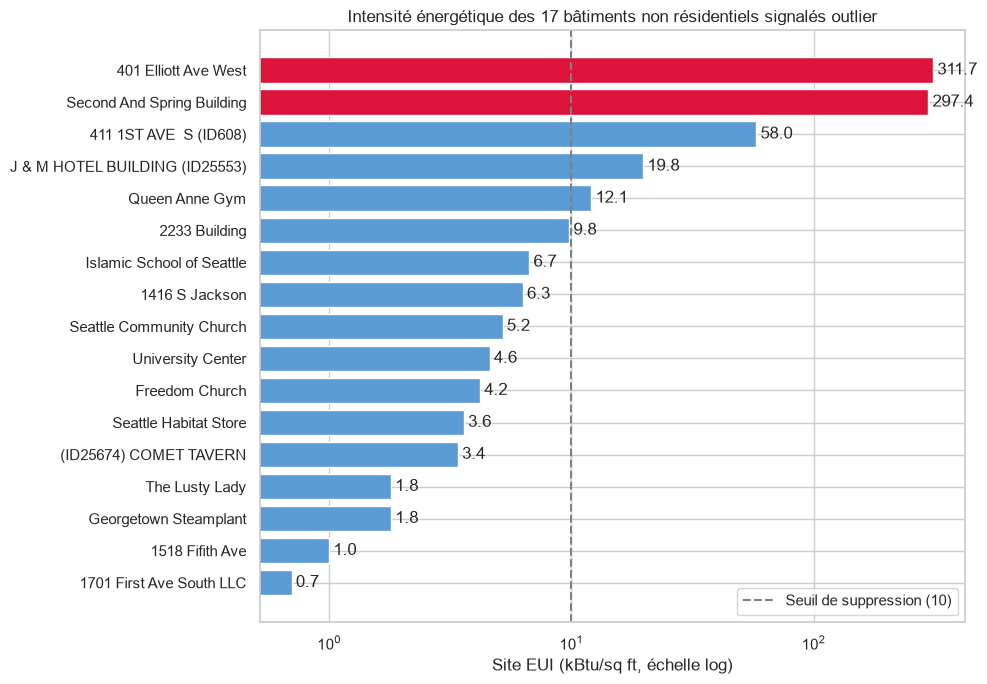

In [ ]:
brut = pd.read_csv(Path("data/2016-building-energy-benchmarking-6af870b7ba821669818300.csv"))

out17 = brut[brut["Outlier"].notna() & ~brut["BuildingType"].str.startswith("Multifamily")].copy()
out17 = out17.sort_values("SiteEUI(kBtu/sf)")

print(f"{len(out17)} bâtiments non résidentiels marqués outlier")
display(out17[["PropertyName", "PrimaryPropertyType", "PropertyGFATotal",
               "SiteEUI(kBtu/sf)", "Outlier"]])

fig, ax = plt.subplots(figsize=(10, 7))
couleurs = out17["Outlier"].map({"Low outlier": "#5b9bd5", "High outlier": "crimson"})
ax.barh(out17["PropertyName"], out17["SiteEUI(kBtu/sf)"], color=couleurs)
ax.set_xscale("log")
ax.axvline(10, color="grey", linestyle="--", label="Seuil de suppression (10)")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_xlabel("Site EUI (kBtu/sq ft, échelle log)")
ax.set_title(f"Intensité énergétique des {len(out17)} bâtiments non résidentiels signalés outlier")
ax.legend()
plt.tight_layout()
plt.show()


cas marqués comme outliers mais pas forcément incohérents comte tenu de la superfice des batiments (Large Office) peut être pertinent pour le modèle pour qu il reconnaisse ce genres de cas:
401 Elliott Ave West
Second And Spring Building
411 1ST AVE  S (ID608)

### Matrices de corrélation par variable cible

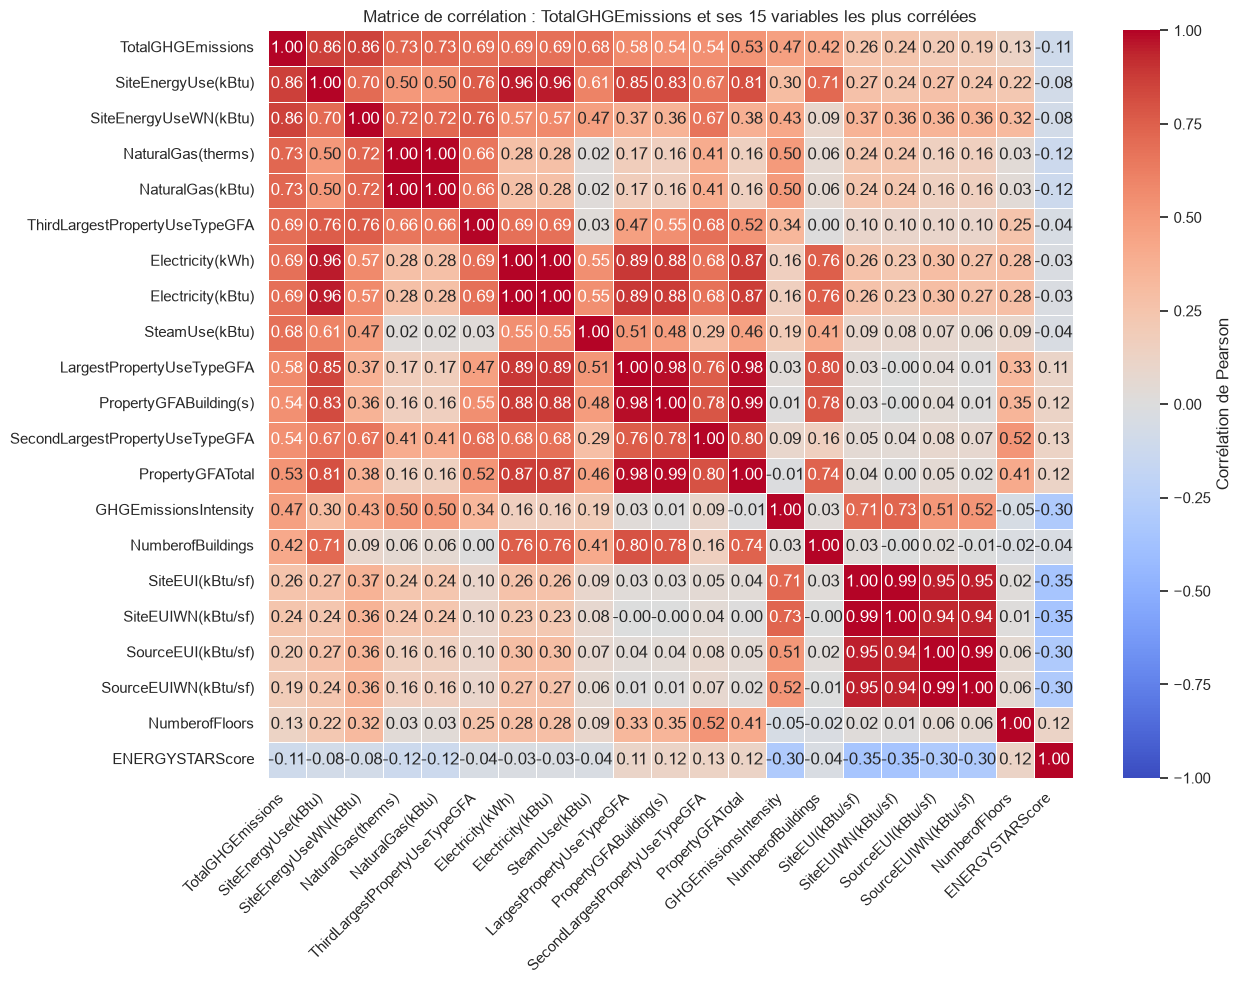

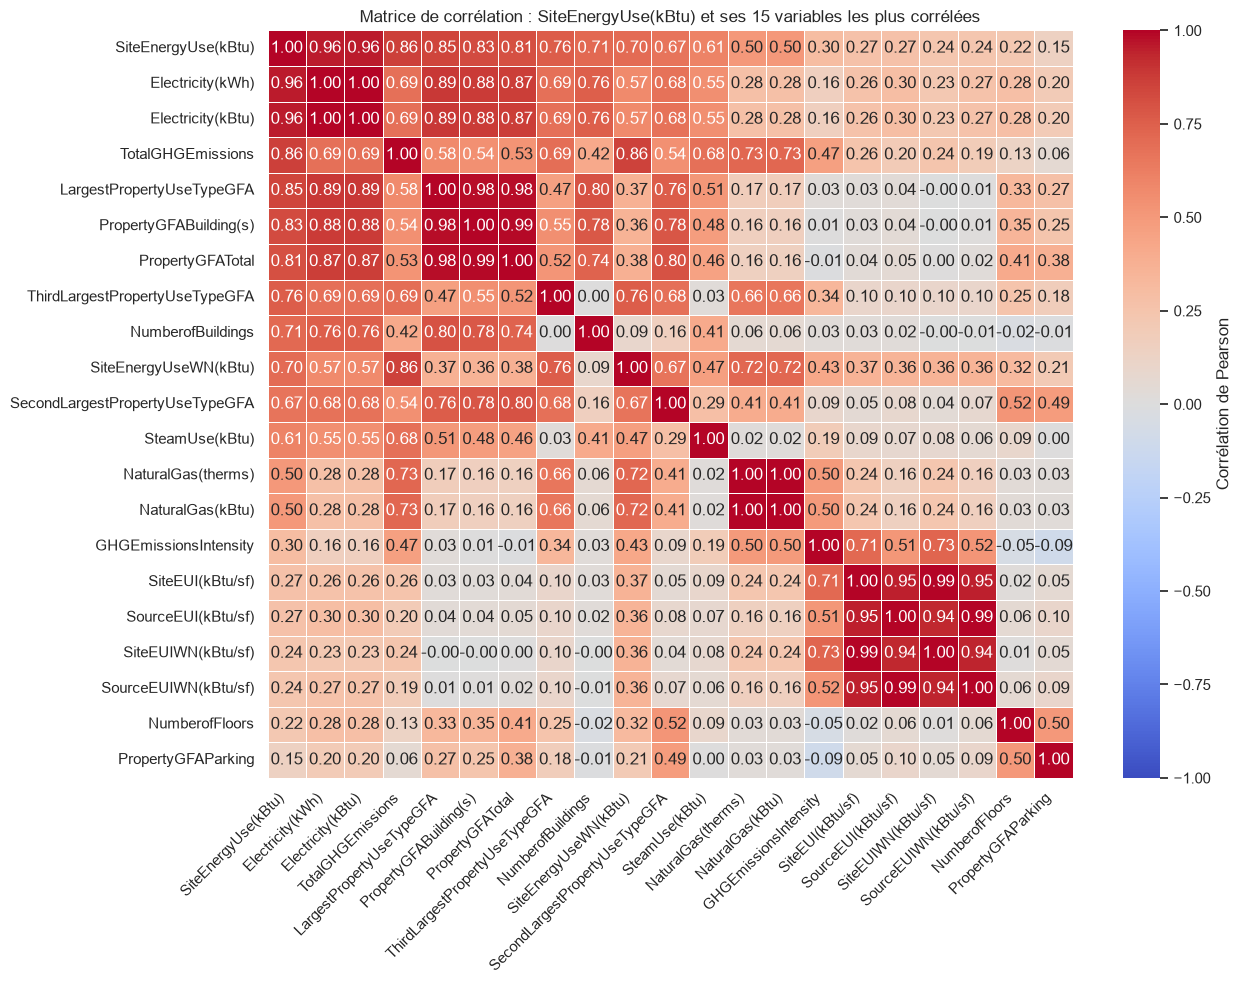

In [ ]:
targets = ["TotalGHGEmissions", "SiteEnergyUse(kBtu)"]
num = df.select_dtypes("number").drop(columns=["OSEBuildingID", "DataYear"])
corr = num.corr()

for t in targets:
    top = corr[t].drop(t).abs().sort_values(ascending=False).head(20).index
    cols = [t, *top]
    fig, ax = plt.subplots(figsize=(13, 10))
    sns.heatmap(corr.loc[cols, cols], annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Corrélation de Pearson"}, ax=ax)
    ax.set_title(f"Matrice de corrélation : {t} et ses 15 variables les plus corrélées")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

colonnes qui data leak:

SiteEUI(kBtu/sf)
SiteEUIWN(kBtu/sf)
SourceEUI(kBtu/sf)
SourceEUIWN(kBtu/sf)
SiteEnergyUseWN(kBtu)
SteamUse(kBtu)
Electricity(kWh)
Electricity(kBtu)
NaturalGas(therms)
NaturalGas(kBtu)
ComplianceStatuts
Years ENERGYSTARCertified

## Supression des colonnes causant du data leak 

In [ ]:
colonnes_a_supprimer = [
    "SiteEUI(kBtu/sf)",
    "SiteEUIWN(kBtu/sf)",
    "SourceEUI(kBtu/sf)",
    "SourceEUIWN(kBtu/sf)",
    "SiteEnergyUseWN(kBtu)",
    "SteamUse(kBtu)",
    "Electricity(kWh)",
    "Electricity(kBtu)",
    "NaturalGas(therms)",
    "NaturalGas(kBtu)",
    "ComplianceStatus",
    "YearsENERGYSTARCertified",
]

df = df.drop(columns=colonnes_a_supprimer)


Matrice de corrélation après supression 

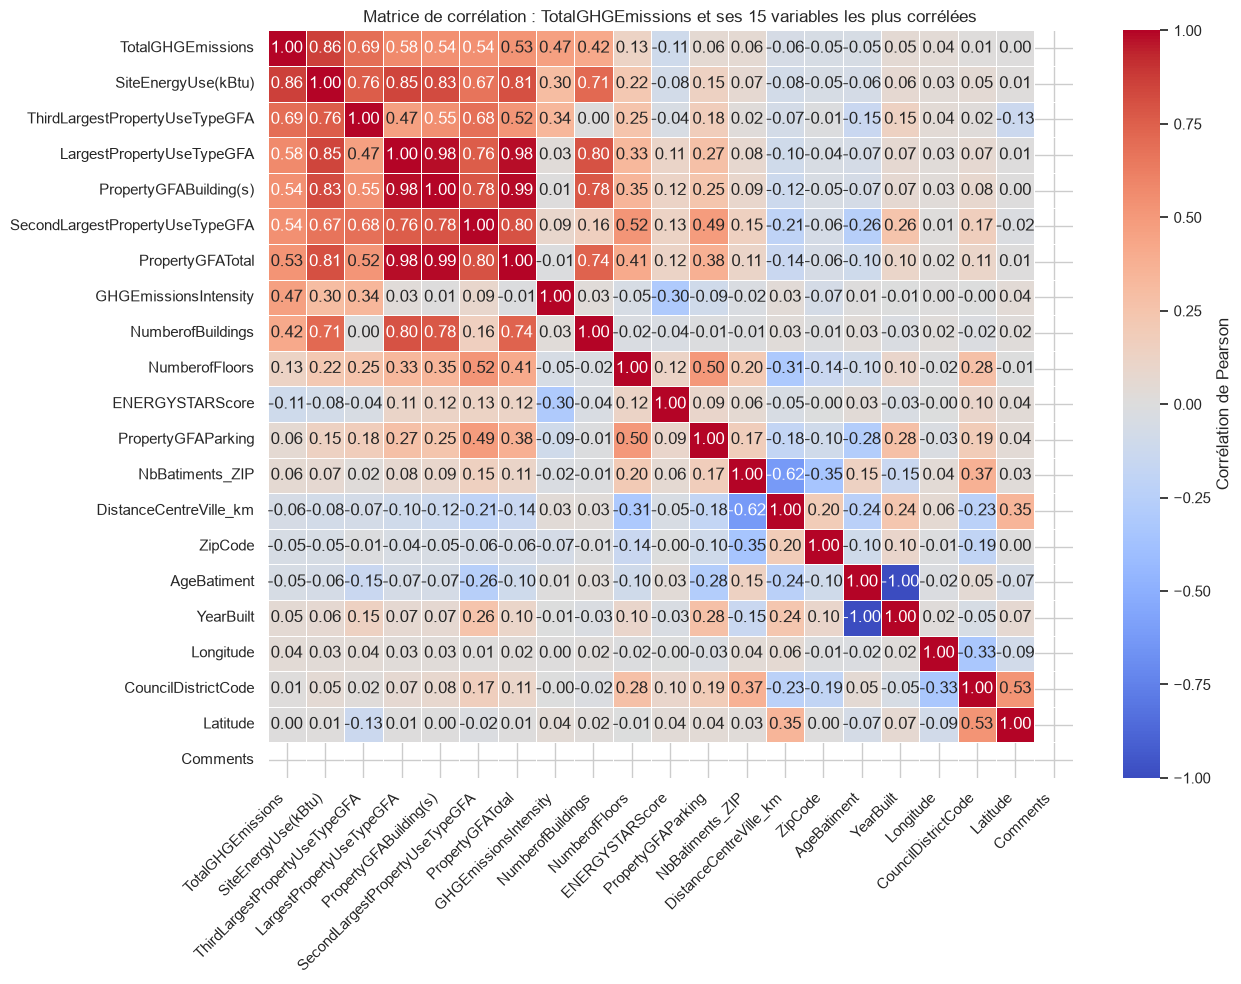

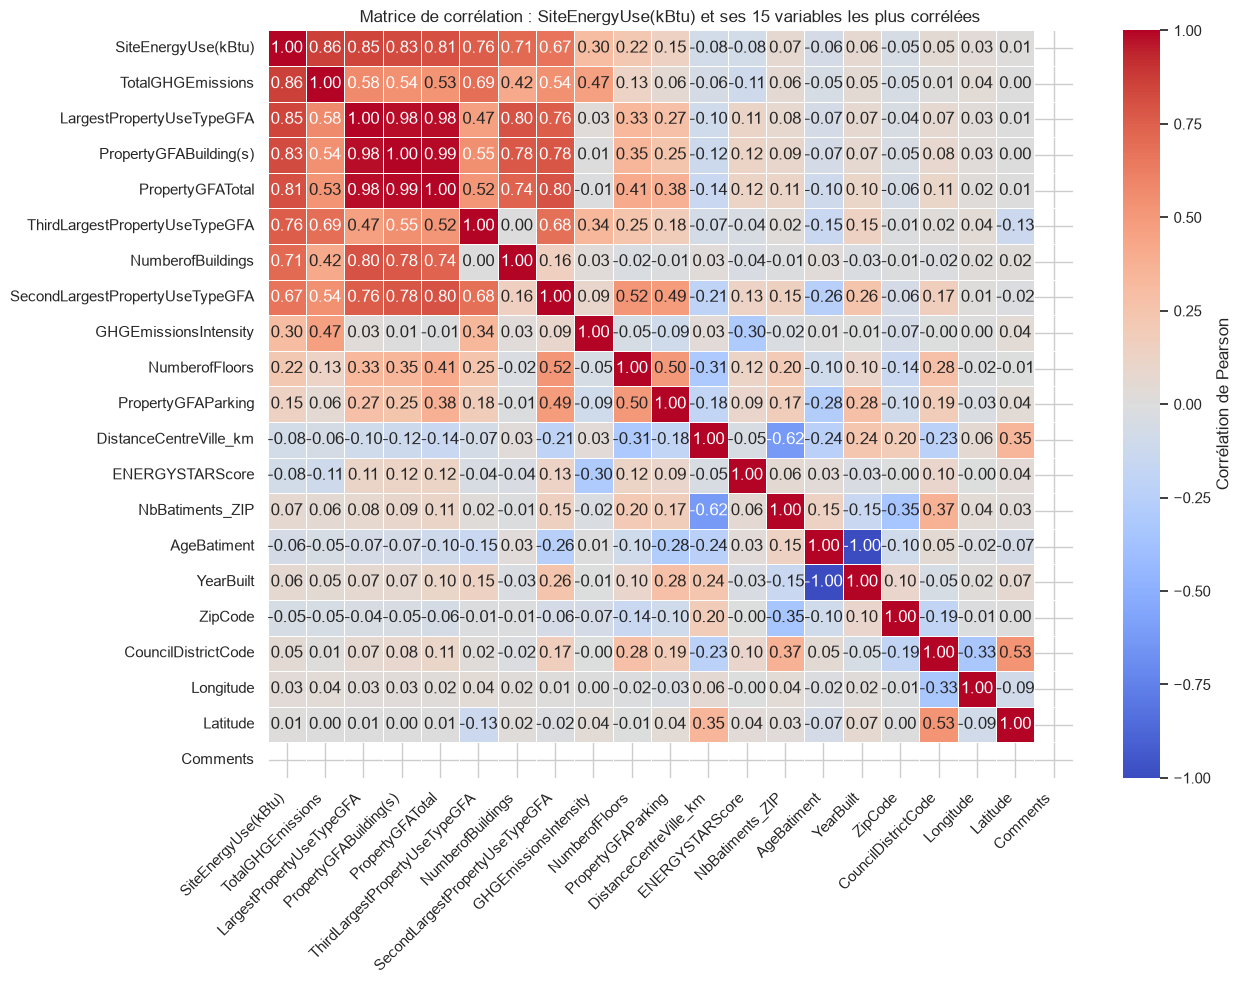

In [ ]:
targets = ["TotalGHGEmissions", "SiteEnergyUse(kBtu)"]
num = df.select_dtypes("number").drop(columns=["OSEBuildingID", "DataYear"])
corr = num.corr()

for t in targets:
    top = corr[t].drop(t).abs().sort_values(ascending=False).head(20).index
    cols = [t, *top]
    fig, ax = plt.subplots(figsize=(13, 10))
    sns.heatmap(corr.loc[cols, cols], annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Corrélation de Pearson"}, ax=ax)
    ax.set_title(f"Matrice de corrélation : {t} et ses 15 variables les plus corrélées")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Energy star score est compliqué a claculer pour l équipe EPA, le cout du calcule est rentable si elle se révèle utile au modèle


# Lien avec la cible


TotalGHGEmissions SiteEnergyUse mis en relation avec surface (PropertyGFATotal) par BuildingType en échelle logaritmique 

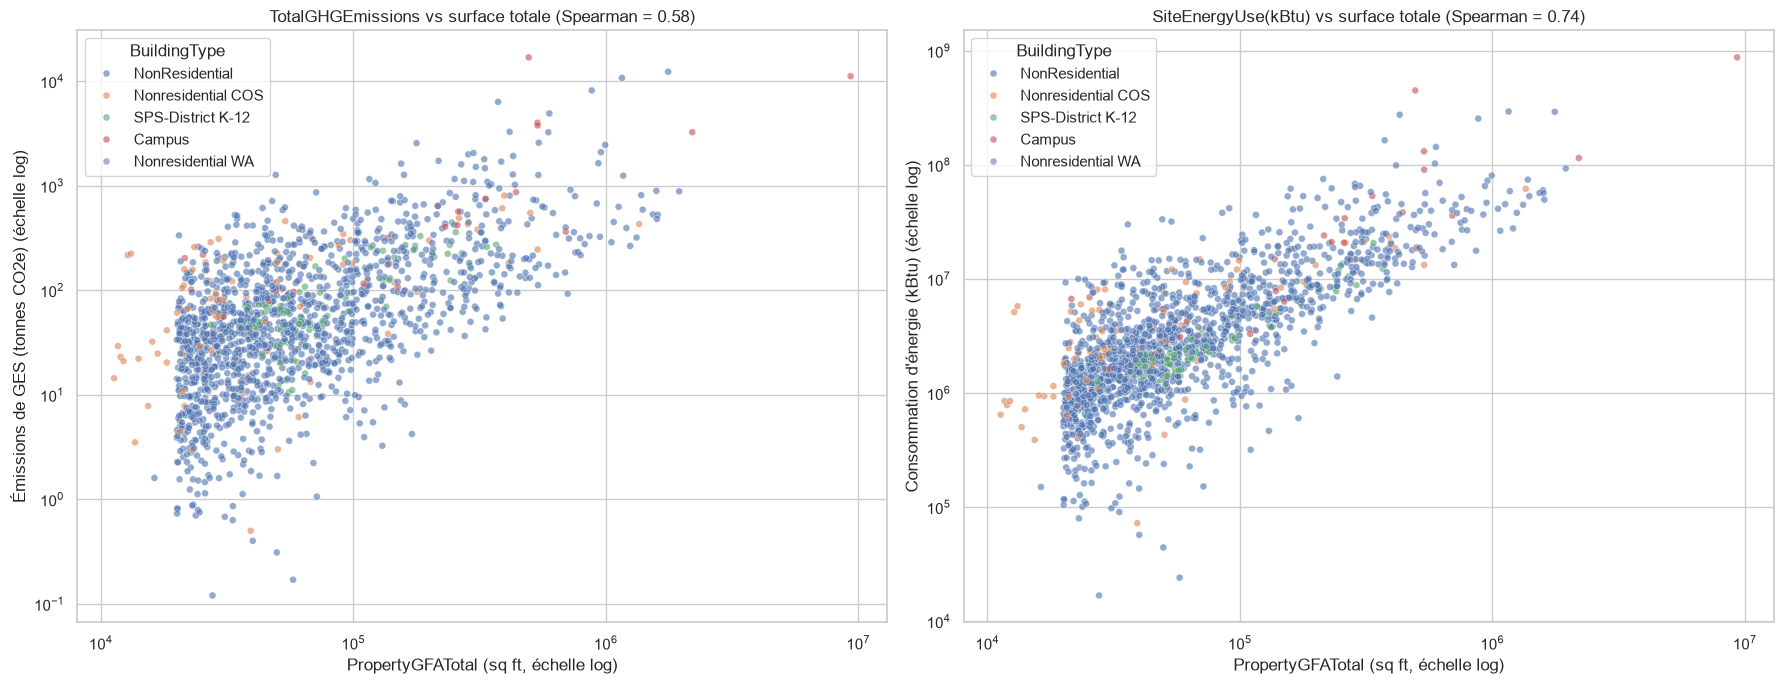

In [ ]:
targets = ["TotalGHGEmissions", "SiteEnergyUse(kBtu)"]
labels = {"TotalGHGEmissions": "Émissions de GES (tonnes CO2e)", "SiteEnergyUse(kBtu)": "Consommation d'énergie (kBtu)"}


fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, t in zip(axes, targets):
    sns.scatterplot(data=nr, x="PropertyGFATotal", y=t, hue="BuildingType", alpha=0.6, s=25, ax=ax)
    ax.set_xscale("log"); ax.set_yscale("log")
    rho = nr[["PropertyGFATotal", t]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{t} vs surface totale (Spearman = {rho:.2f})")
    ax.set_xlabel("PropertyGFATotal (sq ft, échelle log)")
    ax.set_ylabel(f"{labels[t]} (échelle log)")
plt.tight_layout()
plt.show()

Targets mis en relation avec type de batiment (PrimaryPropertyType) 

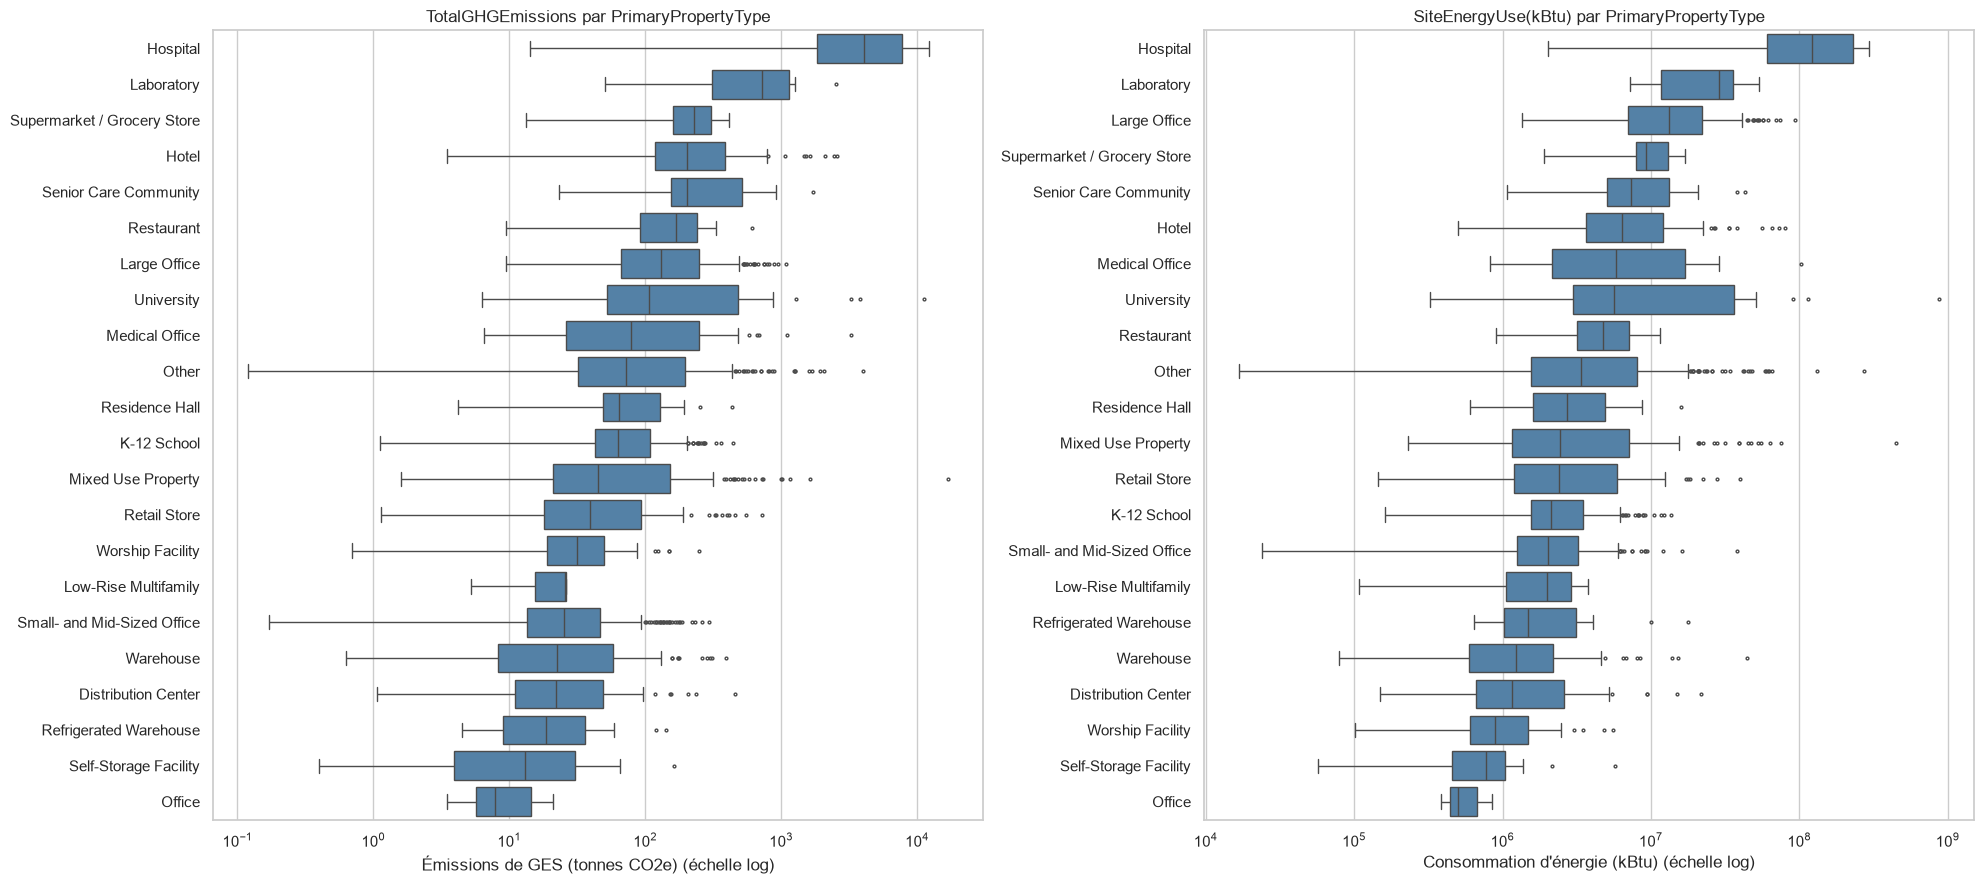

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, t in zip(axes, targets):
    order = nr.groupby("PrimaryPropertyType")[t].median().sort_values(ascending=False).index
    sns.boxplot(data=nr, y="PrimaryPropertyType", x=t, order=order, color="steelblue",
                fliersize=2, ax=ax)
    ax.set_xscale("log")
    ax.set_title(f"{t} par PrimaryPropertyType")
    ax.set_xlabel(f"{labels[t]} (échelle log)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Colinéarité entre variables numériques

9 paires de variables avec |corrélation| >= 0.8


,variable_1,variable_2,corrélation
0,YearBuilt,AgeBatiment,-1.000
1,PropertyGFATotal,PropertyGFABuilding(s),0.990
2,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,0.982
3,PropertyGFATotal,LargestPropertyUseTypeGFA,0.978
4,SiteEnergyUse(kBtu),TotalGHGEmissions,0.860
5,LargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),0.846
6,PropertyGFABuilding(s),SiteEnergyUse(kBtu),0.826
7,PropertyGFATotal,SiteEnergyUse(kBtu),0.810
8,PropertyGFATotal,SecondLargestPropertyUseTypeGFA,0.800


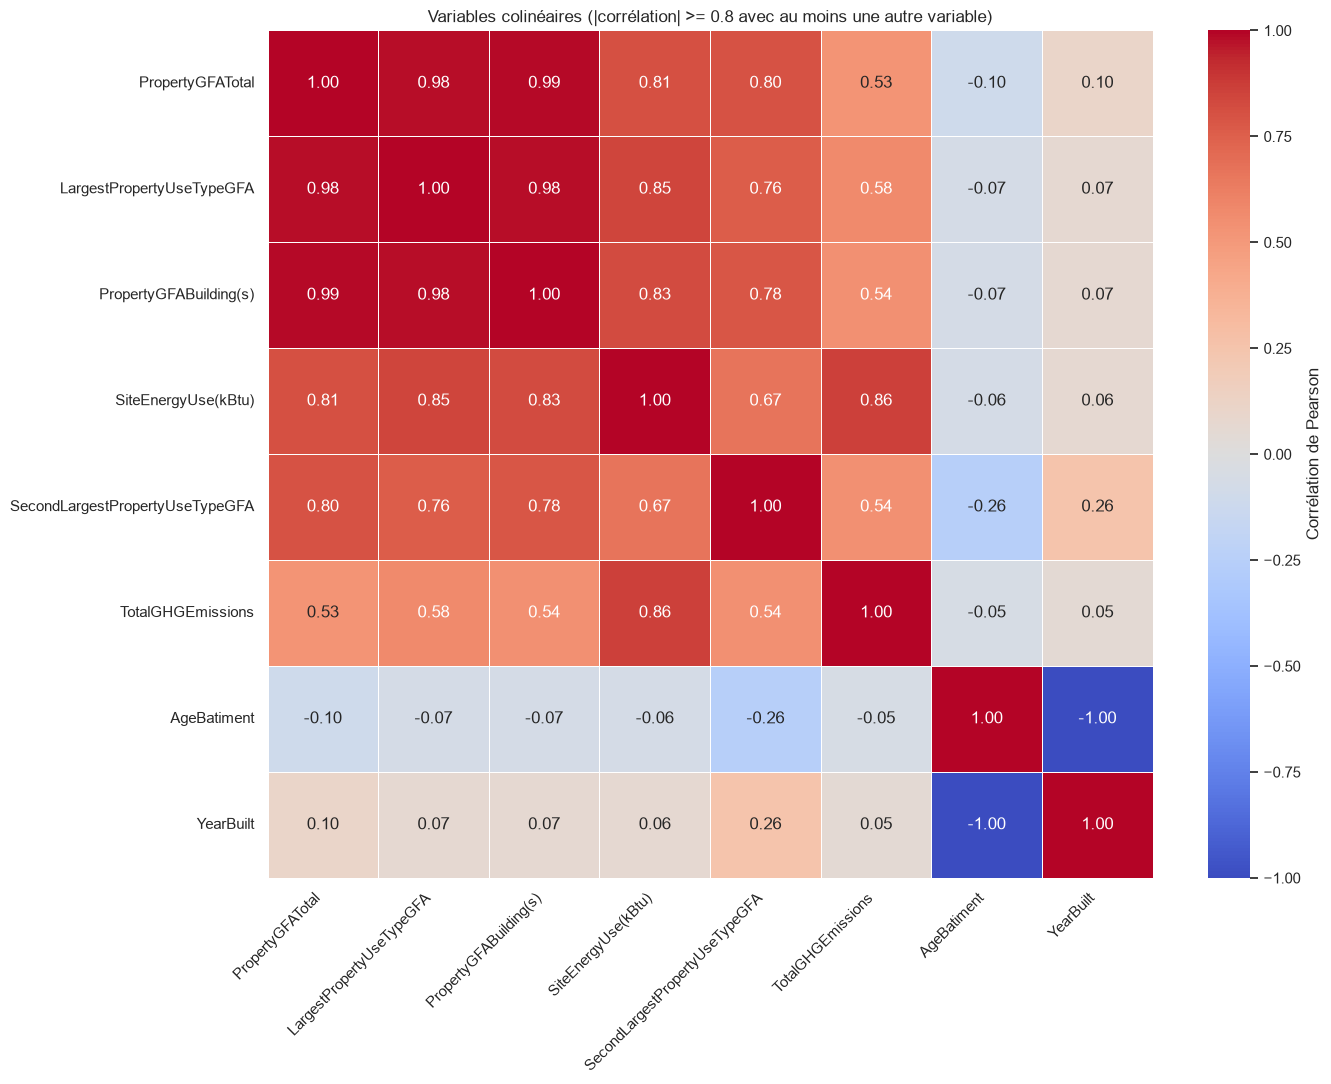

In [ ]:
SEUIL = 0.8   # |corrélation| au-delà de laquelle on parle de colinéarité

num = df.select_dtypes("number").drop(columns=["OSEBuildingID", "DataYear"])
corr = num.corr()

# Paires de variables fortement corrélées (triangle supérieur pour éviter les doublons)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = (corr.where(mask).stack().rename("corrélation").reset_index()
             .rename(columns={"level_0": "variable_1", "level_1": "variable_2"}))
pairs = (pairs[pairs["corrélation"].abs() >= SEUIL]
         .sort_values("corrélation", key=abs, ascending=False).reset_index(drop=True))
print(f"{len(pairs)} paires de variables avec |corrélation| >= {SEUIL}")
with pd.option_context("display.max_rows", None):
    display(pairs.round(3))

# Heatmap restreinte aux variables impliquées dans au moins une paire colinéaire
involved = sorted(set(pairs["variable_1"]) | set(pairs["variable_2"]))
order = corr.loc[involved, involved].abs().sum().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr.loc[order, order], annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Corrélation de Pearson"}, ax=ax)
ax.set_title(f"Variables colinéaires (|corrélation| >= {SEUIL} avec au moins une autre variable)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Property GFA total colinéaire avec PropertyGFABuilding et LargestPropertyUseTypeGFA, garder que l'une d'elles logiquement Property GFA total

AgeBatiment et YearBuilt colinéarité négative, quand l'une augmente l'autre diminue, garder que AgeBatiment comme un peu plus corélée aux targets


